# Alex Vesia: Splitter Pitch Design (2026)

**Design question:** Should Alex Vesia replace his changeup with a vertical splitter thrown from his fastball slot?

**Why it's worth asking:** his changeup sits only 5.7" below his four-seamer in induced vertical break, and he releases it 6.6 (degrees) lower than his fastball. That's a weak shape and a possible tell.

**Author:** Omar Morillo Aldana · Former college player formed in Venezuelan baseball, Driveline-certified hitting coach · [GitHub](https://github.com/OmarMorillo) · [LinkedIn](https://www.linkedin.com/in/omar-morillo-203a9124a/)

## Data

**Source:** Baseball Savant (MLB Advanced Media), Statcast, 2026 regular season. Files and download dates are listed in `data/raw/SOURCES.md`.

- **Pitch-by-pitch:** every pitch Alex Vesia and Trey Yesavage threw in 2026.
- **Leaderboards:** pitch arsenals (velocity), active spin, arm angles, and every MLB splitter grouped by pitcher.
- **Limits:** the splitter is a target, not a pitch Vesia throws, so its value is estimated from comparable pitchers. Yesavage pitched mostly from May to July.

## Contents

1. [What data do we have?](#step-1)
2. [How clean is it?](#step-2)
3. [What does Vesia's arsenal look like?](#step-3)
4. [How separated is the changeup from the fastball?](#step-4)
5. [Does he show the same slot on every pitch?](#step-5)
6. [What does a good MLB splitter look like?](#step-6)
7. [What exactly should Vesia's splitter be?](#step-7)
8. [How would his arsenal look with a splitter?](#step-8)
9. [How would Vesia benefit? The Yesavage comparison](#step-9)
10. [What's the story?](#step-10)
11. [So what, limitations and next steps](#so-what)

<a id="step-1"></a>
## Step 1: What data do we have?

Before recommending a new pitch for Alex Vesia, I need to know exactly what data I'm working with and how much of it there is. A pitching coordinator's first question about any recommendation is where the numbers come from and how many pitches stand behind them, and that matters here because his changeup, the pitch I'm proposing to replace, has a sample of only 149 pitches.

In this step I load Vesia's 2026 pitch-by-pitch file from Baseball Savant, count how many of each pitch he threw, and check that the dates cover his full regular season. Then I load three league leaderboards, with pitch velocities, active spin and arm angles, and pull his row from each one, so his numbers can be compared with the rest of MLB in the steps that follow.

By the end of this step I should know how many pitches Vesia threw in total and by type, his first and last game of the season, and his velocity, active spin and arm angle as the league sees them.

### 1.1 Import libraries

Before touching any data, I load the three libraries this notebook relies on and give each one a short nickname. pandas, shortened to `pd`, reads the Savant CSV files into tables that I can filter, count and average. numpy, shortened to `np`, handles the math, and I'll need it in Step 2 to calculate the angle at which each pitch enters the strike zone. matplotlib's pyplot, shortened to `plt`, draws every chart in the project, from the movement plots to the final summary chart.

In [1]:
# STEP 1.1 — Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter("ignore", pd.errors.PerformanceWarning)  # hides a harmless speed warning when adding columns

### 1.2 Load Vesia's pitches

Here I read Vesia's pitch-by-pitch file into a table called `vesia`. Each row is one pitch he threw in a 2026 regular-season game, and each column is something Statcast measured about that pitch, such as its speed, spin, movement, release point and result. Printing its shape shows how many rows and columns came in.

In [2]:
# STEP 1.2 — Load Vesia's pitches
vesia = pd.read_csv("../data/raw/vesia_pitches_2026.csv")
print(vesia.shape)

(1078, 119)


**What I found:** Vesia's 2026 file has 1,078 rows and 119 columns, so every number about him in this project comes from 1,078 entries recorded in regular-season games.

### 1.3 Vesia's pitch counts

Next I count how many of each pitch Vesia threw by applying `.value_counts()` to the `pitch_name` column. I add `dropna=False` so the count also includes pitches that Statcast didn't classify, which show up as blank values instead of being skipped silently.

In [3]:
# STEP 1.3 — Pitch counts by type
vesia["pitch_name"].value_counts(dropna=False)

pitch_name
4-Seam Fastball    601
Slider             315
Changeup           149
NaN                 13
Name: count, dtype: int64

**What I found:** Vesia threw 601 four-seam fastballs (56%), 315 sliders (29%) and 149 changeups (14%) in 2026, plus 13 rows that Statcast left unclassified, which I examine and remove in Step 2. The changeup, the pitch this project proposes to replace, has the smallest sample of the three, so its numbers should be read with that in mind.

### 1.4 Vesia's date range

To confirm that the file covers his whole season, I find the dates of his first and last appearances. The 2026 regular season opened on March 26 and ended on September 27. Dates are stored as text in year-month-day order, which sorts the same way real dates do, so `.min()` and `.max()` return his earliest and latest games.

In [4]:
# STEP 1.4 — Date range
vesia_first_game = vesia["game_date"].min()
vesia_last_game = vesia["game_date"].max()
print(f"Vesia's first appearance of the 2026 season was on {vesia_first_game} and his last was on {vesia_last_game}.")

Vesia's first appearance of the 2026 season was on 2026-03-27 and his last was on 2026-09-27.


**What I found:** Vesia's file runs from March 27 to September 27, 2026. He pitched the day after Opening Day and in the final game of the regular season, so the data covers his full season with no missing stretch at either end.

### 1.5 Load the three leaderboards

The pitch-by-pitch file shows what Vesia did, but not how he compares with the rest of the league. For that I load three Baseball Savant leaderboards. The pitch arsenal table gives every pitcher's average velocity for each pitch type. The active spin table gives the share of each pitch's spin that actually moves the ball. The arm angle table gives each pitcher's arm slot for the season. I print their shapes in a single line to confirm that each file came in complete.

In [5]:
# STEP 1.5 — Load the three leaderboards
lb_arsenal = pd.read_csv("../data/raw/lb_pitch_arsenals_2026.csv")
lb_spin = pd.read_csv("../data/raw/lb_active_spin_2026.csv")
lb_arm_slot = pd.read_csv("../data/raw/lb_arm_angles_2026.csv")
print(lb_arsenal.shape, lb_spin.shape, lb_arm_slot.shape)

(333, 12) (713, 12) (294, 10)


**What I found:** The three leaderboards loaded completely: 333 pitchers in the arsenal table, 713 in the active spin table and 294 in the arm angle table. The counts differ because Savant applies a different minimum number of pitches to each leaderboard, so a pitcher can appear in one table and not another.

### 1.6 Vesia in each leaderboard

Finally, I pull Vesia's row from each leaderboard so his league numbers sit together in one place. Each file names its player column differently: the arsenal table uses `last_name, first_name`, the active spin table uses `entity_name`, and the arm angle table uses `pitcher_name`. In all three, his name is written "Vesia, Alex". I wrap each result in `display()` so all three tables appear, since a cell otherwise shows only its last result.

In [6]:
# STEP 1.6 — Vesia's row in each leaderboard
display(lb_arsenal[lb_arsenal["last_name, first_name"] == "Vesia, Alex"][["last_name, first_name", "ff_avg_speed", "sl_avg_speed", "ch_avg_speed"]])
display(lb_spin[lb_spin["entity_name"] == "Vesia, Alex"][["entity_name", "active_spin_fourseam", "active_spin_slider", "active_spin_changeup"]])
display(lb_arm_slot[lb_arm_slot["pitcher_name"] == "Vesia, Alex"][["pitcher_name", "pitch_hand", "ball_angle"]])

,"last_name, first_name",ff_avg_speed,sl_avg_speed,ch_avg_speed
262,"Vesia, Alex",92.1,84.4,82.8


,entity_name,active_spin_fourseam,active_spin_slider,active_spin_changeup
135,"Vesia, Alex",97.8,44.9,99.1


,pitcher_name,pitch_hand,ball_angle
216,"Vesia, Alex",L,69.5


**What I found:** Vesia averaged 92.1 mph on his four-seamer, 84.4 mph on his slider and 82.8 mph on his changeup in 2026. His four-seamer and changeup spin with almost perfect efficiency (97.8% and 99.1% active spin), while his slider sits at 44.9%, the typical profile of a gyro slider. His arm angle of 69.5 (degrees) is the highest of any pitcher in the 2026 arm angle leaderboard, which means he throws from a nearly over-the-top slot. That changeup efficiency is the first sign of the problem: nearly all of its spin creates lift, which helps it stay up like a fastball instead of dropping.

### Data dictionary

| Column | File | Meaning | Units |
|---|---|---|---|
| pitch_name | vesia | Pitch type assigned by Statcast | text |
| game_date | vesia | Date of the game | YYYY-MM-DD |
| ff_avg_speed / sl_avg_speed / ch_avg_speed | lb_arsenal | Season average velocity of the four-seamer, slider and changeup | mph |
| active_spin_fourseam / _slider / _changeup | lb_spin | Share of the pitch's spin that creates movement | % |
| pitch_hand | lb_arm_slot | Throwing hand (L or R) | text |
| ball_angle | lb_arm_slot | Season arm angle at release | degrees |

The full dictionary, including the columns added later, is in `data_dictionary.md`.

**What I found in Step 1:** The data covers Vesia's full 2026 regular season, from March 27 to September 27, with 1,078 rows: 601 four-seamers, 315 sliders, 149 changeups and 13 unclassified entries that I examine in Step 2. The league leaderboards place him at a 69.5 (degrees) arm angle, the highest in MLB, with a 92.1 mph four-seamer and an 82.8 mph changeup that spins with 99.1% efficiency. The changeup's small sample and its fastball-like spin are the two facts I carry into the next steps.

<a id="step-2"></a>
## Step 2: How clean is it?

Before measuring anything, I need to be sure that every row in the table is a real pitch with complete tracking data. A single bad row can pull an average in the wrong direction, and with only 149 changeups, a few wrong values could change how big the problem looks. A pitching coordinator should be able to trust that each number in the report comes from pitches Vesia actually threw.

In this step I first look at the 13 rows without a pitch type to understand what they are before removing them. Then I check that the remaining pitches have no missing values in the columns this project depends on, and that every value falls within a range that makes sense for a big-league pitch. Finally, I add three new columns that the rest of the project needs: vertical break in inches, horizontal break in inches measured toward his arm side, and the vertical approach angle, which describes how steeply each pitch enters the strike zone. I save the result as a clean file so every later step starts from the same data.

### 2.1 What are the 13 blank rows?

Step 1 showed 13 rows with no pitch type. Instead of deleting them right away, I first look at what happened on those pitches by showing their `description` column, which records the result of each pitch. Knowing why a row is blank tells me whether removing it could hide something important, or whether it was never a real pitch to begin with.

In [7]:
# STEP 2.1 — Inspect the blank rows
blank_rows = vesia[vesia["pitch_name"].isna()]
blank_rows[["game_date", "description", "release_speed", "pitch_name"]]

,game_date,description,release_speed,pitch_name
234,2026-08-19,automatic_strike,NaN,NaN
440,2026-07-17,automatic_ball,NaN,NaN
441,2026-07-17,automatic_ball,NaN,NaN
442,2026-07-17,automatic_ball,NaN,NaN
443,2026-07-17,automatic_ball,NaN,NaN
481,2026-07-08,automatic_ball,NaN,NaN
482,2026-07-08,automatic_ball,NaN,NaN
483,2026-07-08,automatic_ball,NaN,NaN
484,2026-07-08,automatic_ball,NaN,NaN
625,2026-06-17,automatic_ball,NaN,NaN


**What I found:** The 13 rows without a pitch type are not pitches. Twelve of them come from three intentional walks (June 17, July 8 and July 17): each is recorded as four automatic balls to the same hitter, and the `events` column marks the last one as `intent_walk`. The other row is an automatic strike on August 19, at a 0–0 count, from a pitch-clock violation. Since no ball was thrown on any of them, they have no speed, spin or movement, and I can remove them safely.

### 2.2 Remove the non-pitches

Now that I know the 13 blank rows are intentional walks and a pitch-clock violation, I remove them and keep only real pitches in a new table called `vesia_clean`. I keep the original `vesia` table untouched, so I can always go back and check what the raw file contained, and I add `.copy()` so the new table is fully separate and new columns can be added to it safely.

In [8]:
# STEP 2.2 — Keep only real pitches
vesia_clean = vesia.dropna(subset=["pitch_name"]).copy()
print(f"Removed {len(vesia) - len(vesia_clean)} rows. {len(vesia_clean):,} pitches left.")

Removed 13 rows. 1,065 pitches left.


**What I found:** Removing the 13 non-pitches leaves 1,065 real pitches in `vesia_clean`. The original `vesia` table stays unchanged, so the raw data is still available for checking.

### 2.3 Check for missing values

Removing the non-pitches fixed the blank pitch types, but a pitch could still be missing one of its measurements, such as spin or movement. Here I count the blank values in the fifteen columns this project depends on: velocity, spin rate, spin axis, horizontal and vertical movement, arm angle, the three release-point columns, and the six velocity and acceleration values I'll use to calculate approach angle.

In [9]:
# STEP 2.3 — Missing values in the key columns
key_cols = ["release_speed", "release_spin_rate", "spin_axis", "pfx_x", "pfx_z", "arm_angle",
            "release_pos_x", "release_pos_z", "release_extension",
            "vx0", "vy0", "vz0", "ax", "ay", "az"]
vesia_clean[key_cols].isna().sum()

release_speed        0
release_spin_rate    0
spin_axis            0
pfx_x                0
pfx_z                0
arm_angle            0
release_pos_x        0
release_pos_z        0
release_extension    0
vx0                  0
vy0                  0
vz0                  0
ax                   0
ay                   0
az                   0
dtype: int64

**What I found:** None of the 1,065 pitches is missing a value in the 15 columns this project depends on, from velocity and spin to movement, arm angle, release point and the six values used for approach angle. Once the intentional walks and the pitch-clock violation were removed, every remaining pitch has complete tracking data.

### 2.4 Check that the values make sense

Having no blanks doesn't guarantee that every value is right. A tracking error could record an impossible speed or a spin rate far outside anything a human can produce. Here I look at the smallest and largest value of the measurements that matter most for this project: velocity, spin rate, spin direction, horizontal and vertical movement, arm angle and extension.

In [10]:
# STEP 2.4 — Value ranges
range_cols = ["release_speed", "release_spin_rate", "spin_axis", "pfx_x", "pfx_z", "arm_angle", "release_extension"]
vesia_clean[range_cols].describe().loc[["min", "max"]].round(2)

,release_speed,release_spin_rate,spin_axis,pfx_x,pfx_z,arm_angle,release_extension
min,79.7,1666.0,125.0,-0.96,-0.12,55.5,5.7
max,94.7,2755.0,246.0,1.37,2.16,83.1,7.0


**What I found:** Every measurement falls within a realistic range for a big-league left-hander: velocity from 79.7 to 94.7 mph, spin rate from 1,666 to 2,755 rpm, spin direction from 125 (degrees) to 246 (degrees), and extension from 5.7 to 7.0 feet. No value points to a tracking error, so I keep all 1,065 pitches. One number stands out: his arm angle ranges from 55.5 (degrees) to 83.1 (degrees) across all pitches, a spread of almost 28 (degrees), which I break down by pitch type in Step 5.

### 2.5 Movement in inches, measured toward his arm side

Statcast records movement in feet, but pitch designers talk about it in inches, so I convert both directions by multiplying by 12. The vertical column becomes induced vertical break, or IVB: how many inches a pitch rises or drops compared with a ball thrown with no spin.

The horizontal column needs one more step. Statcast measures it from the catcher's point of view, so a pitch that runs toward a pitcher's arm side reads as positive for a lefty but negative for a righty. To compare Vesia with right-handed pitchers later in the project, I create a column called `hb_arm` where arm-side movement is always positive, whichever hand the pitcher throws with.

In [11]:
# STEP 2.5 — IVB and arm-side horizontal break, in inches
vesia_clean["ivb"] = vesia_clean["pfx_z"] * 12
vesia_clean["hb_arm"] = np.where(vesia_clean["p_throws"] == "R", -vesia_clean["pfx_x"] * 12, vesia_clean["pfx_x"] * 12)
vesia_clean[["ivb", "hb_arm"]].describe().loc[["min", "max"]].round(1)

,ivb,hb_arm
min,-1.4,-11.5
max,25.9,16.4


**What I found:** Converted to inches, Vesia's pitches range from 1.4" of drop to 25.9" of rise in induced vertical break, and from 11.5" toward his glove side to 16.4" toward his arm side. The negative horizontal values belong to his slider, which breaks away from left-handed hitters, while his four-seamer and changeup both move toward his arm side. `hb_arm` is horizontal break in inches, positive toward the pitcher's arm side, so pitchers of either hand can be compared directly.

### 2.6 Vertical approach angle

Vertical approach angle, or VAA, is the angle at which a pitch crosses the front of home plate. A flatter angle, closer to zero, makes a high fastball look like it's rising; a steeper angle makes a pitch look like it's dropping. Statcast doesn't give this number directly, so I calculate it from each pitch's velocity and acceleration at release, using the standard formula from pitch-tracking research: the ball's forward speed at the front of the plate, the time it took to get there, its vertical speed at that moment, and finally the angle between the two.

In [12]:
# STEP 2.6 — Vertical approach angle (VAA)
vy_f = -np.sqrt(vesia_clean["vy0"] ** 2 - 2 * vesia_clean["ay"] * (50 - 17/12))
t = (vy_f - vesia_clean["vy0"]) / vesia_clean["ay"]
vz_f = vesia_clean["vz0"] + vesia_clean["az"] * t
vesia_clean["vaa"] = -np.degrees(np.arctan(vz_f / vy_f))
vesia_clean["vaa"].describe().round(2)

count    1065.00
mean       -5.51
std         1.78
min       -10.26
25%        -6.97
50%        -5.04
75%        -4.08
max        -1.90
Name: vaa, dtype: float64

**What I found:** Across all 1,065 pitches, Vesia's pitches cross the front of the plate at an average vertical approach angle of −5.51 (degrees). Half of them fall between −6.97 (degrees) and −4.08 (degrees), and the full range runs from a very flat −1.90 (degrees) to a steep −10.26 (degrees). Every value is negative because the ball is always moving downward when it arrives; the closer the angle is to zero, the flatter the pitch looks to the hitter.

VAA is the result the hitter sees, but it depends heavily on induced vertical break. A pitch with a lot of IVB falls less on its way to the plate, so it arrives on a flatter path; a pitch with little IVB falls more and arrives steeply. That is why the two numbers belong together in this project: Vesia's riding four-seamer should produce his flattest angles, and a splitter would sit at the opposite end, with very little IVB, a steep approach angle and the same release point as the fastball. The bigger that contrast, the harder it is for a hitter to tell the two pitches apart out of the hand.

### 2.7 Save the clean data

The clean table now holds 1,065 real pitches with three new columns. I save it as a new file in the `data/clean` folder so every step that follows starts from exactly the same data, and anyone rerunning the project gets the same results. The original Savant file in `data/raw` stays untouched. To confirm the save worked, I read the new file back in and check its size.

In [13]:
# STEP 2.7 — Save the clean table
vesia_clean.to_csv("../data/clean/vesia_clean_2026.csv", index=False)
print(pd.read_csv("../data/clean/vesia_clean_2026.csv").shape)

(1065, 122)


**What I found:** The clean table saved correctly to `data/clean/vesia_clean_2026.csv`. Reading it back returns 1,065 rows and 122 columns: the 119 original Statcast columns plus induced vertical break, arm-side horizontal break and vertical approach angle.

### QA notes

| Issue | Rows affected | Decision |
|---|---|---|
| Rows with no pitch type | 13 | Removed: 12 automatic balls from three intentional walks and 1 automatic strike from a pitch-clock violation. No ball was thrown. |
| Missing values in the 15 key columns | 0 | Nothing to fix |
| Impossible or unrealistic values | 0 | All ranges fit an MLB left-hander; all pitches kept |
| Movement in feet, horizontal break from the catcher's view | All | Converted to inches; created `hb_arm` with arm side positive |
| No approach angle in Statcast | All | Calculated `vaa` from release velocity and acceleration |

**What I found in Step 2:** Vesia's 2026 data is clean and complete. The only rows I removed were 13 entries that were not real pitches. The remaining 1,065 pitches have no missing values in any of the columns this project uses, and every measurement falls within a realistic range. I added three columns that pitch designers use, and the clean table is saved, so every step that follows starts from the same 1,065 pitches.

<a id="step-3"></a>
## Step 3: What does Vesia's arsenal look like?

With clean data in hand, I can now describe each of Vesia's three pitches the way a pitch designer would: how hard he throws it, how fast and in what direction it spins, how much of that spin creates movement, how much it rises or drops, how far it moves sideways, the arm slot it comes from and the angle at which it reaches the plate. I also measure how each pitch performs, using whiff rate and expected wOBA allowed, so the shape of every pitch can be read next to its results.

This profile matters because a new pitch has to fit the arsenal a pitcher already has. A pitching coordinator won't add a splitter just because it is a good pitch in general; they need to see where Vesia's current pitches sit, which areas of movement are already covered, and which are empty. The movement chart at the end of this step makes that visible in a single picture.

### 3.1 Load the clean data

Step 3 starts from the clean file saved at the end of Step 2, not from the table still in memory. That way this step can be rerun on its own, and anyone who opens the project later gets exactly the same 1,065 pitches I used. I also confirm that all 149 changeups are in the table, since the preview below shows only the most recent pitches.

In [14]:
# STEP 3.1 — Load the clean data
vesia_clean = pd.read_csv("../data/clean/vesia_clean_2026.csv")
print(vesia_clean.shape)
display(vesia_clean[["pitch_name", "ivb", "hb_arm", "vaa"]].head())
display(vesia_clean[vesia_clean["pitch_name"] == "Changeup"][["pitch_name", "ivb", "hb_arm", "vaa"]].head())

(1065, 122)


,pitch_name,ivb,hb_arm,vaa
0,4-Seam Fastball,19.56,6.84,-4.468625
1,4-Seam Fastball,21.00,6.84,-5.204783
2,4-Seam Fastball,20.40,5.04,-4.876658
3,Slider,5.52,-4.56,-6.874398
4,4-Seam Fastball,21.48,3.84,-3.077370


,pitch_name,ivb,hb_arm,vaa
10,Changeup,17.16,9.60,-7.300771
13,Changeup,14.52,12.12,-6.897661
16,Changeup,14.40,11.04,-8.455453
23,Changeup,17.40,9.84,-7.872309
31,Changeup,15.60,11.64,-6.226865


**What I found:** The clean file loads with 1,065 pitches and 122 columns, and the three columns created in Step 2 have values in every row shown. The first rows are the last pitches of his season, mostly four-seamers, because Savant lists the most recent pitches first; the second table confirms that his changeups are in the table, with 13 to 17 inches of rise and 8 to 12 inches of arm-side run.

### 3.2 How often he throws each pitch

Before describing what each pitch looks like, I measure how often Vesia uses it. Usage shows which pitches carry his game and which play a supporting role, and it tells a reader how much data stands behind each pitch's numbers. I count the pitches of each type and turn those counts into percentages of his 1,065 pitches.

In [15]:
# STEP 3.2 — Usage by pitch type
counts = vesia_clean["pitch_name"].value_counts()
usage_pct = (vesia_clean["pitch_name"].value_counts(normalize=True) * 100).round(1)
usage = pd.DataFrame({"pitches": counts, "usage_pct": usage_pct})
usage

,pitches,usage_pct
pitch_name,,
4-Seam Fastball,601,56.4
Slider,315,29.6
Changeup,149,14.0


**What I found:** Vesia is a fastball-first pitcher. He threw his four-seamer 601 times (56.4%), his slider 315 times (29.6%) and his changeup 149 times (14.0%). Nearly six of every seven pitches are a four-seamer or a slider, which means the changeup is a third pitch he uses sparingly, and it is the pitch with the least data behind it.

### 3.3 The shape of each pitch

This is the core profile of his arsenal. For each pitch type I calculate the average of seven measurements: velocity, spin rate, spin direction, induced vertical break, arm-side horizontal break, arm angle and vertical approach angle. I order the rows the same way as the usage table, from most to least used, so the two tables line up.

In [16]:
# STEP 3.3 — Shape table by pitch type
shape_cols = ["release_speed", "release_spin_rate", "spin_axis", "ivb", "hb_arm", "arm_angle", "vaa"]
shape = vesia_clean.groupby("pitch_name")[shape_cols].mean().round(1)
shape = shape.reindex(usage.index)
shape

,release_speed,release_spin_rate,spin_axis,ivb,hb_arm,arm_angle,vaa
pitch_name,,,,,,,
4-Seam Fastball,92.1,2512.4,167.2,21.2,4.3,69.0,-4.2
Slider,84.4,2378.0,216.3,3.3,-5.8,73.8,-7.6
Changeup,82.8,1886.5,135.6,15.5,10.1,62.5,-6.5


**What I found:** Each pitch has a clearly different shape. The four-seamer averages 92.1 mph with 21.2 inches of rise and arrives at a flat −4.2 (degrees). The slider averages 84.4 mph, drops to 3.3 inches of rise, breaks 5.8 inches to his glove side and arrives at the steepest angle, −7.6 (degrees). The changeup averages 82.8 mph but keeps 15.5 inches of rise, only 5.7 inches less than his fastball, while running 10.1 inches to his arm side. It also leaves his hand at a 62.5 (degrees) arm angle, 6.5 (degrees) lower than his four-seamer, while the slider comes out about 5 (degrees) higher.

### 3.4 How efficiently each pitch spins

Spin rate tells how fast a pitch spins, but not how much of that spin actually moves the ball. Active spin, also called spin efficiency, is the share of spin that creates movement; the rest spins like a bullet and adds almost nothing. Statcast doesn't include it in the pitch-by-pitch file, so I take Vesia's values from the active spin leaderboard and add them to the shape table as a new column.

In [17]:
# STEP 3.4 — Add active spin
lb_spin = pd.read_csv("../data/raw/lb_active_spin_2026.csv")
vesia_spin = lb_spin[lb_spin["entity_name"] == "Vesia, Alex"].iloc[0]
spin_map = {"4-Seam Fastball": vesia_spin["active_spin_fourseam"],
            "Slider": vesia_spin["active_spin_slider"],
            "Changeup": vesia_spin["active_spin_changeup"]}
shape["active_spin"] = shape.index.map(spin_map)
shape

,release_speed,release_spin_rate,spin_axis,ivb,hb_arm,arm_angle,vaa,active_spin
pitch_name,,,,,,,,
4-Seam Fastball,92.1,2512.4,167.2,21.2,4.3,69.0,-4.2,97.8
Slider,84.4,2378.0,216.3,3.3,-5.8,73.8,-7.6,44.9
Changeup,82.8,1886.5,135.6,15.5,10.1,62.5,-6.5,99.1


**What I found:** Vesia's four-seamer (97.8%) and changeup (99.1%) turn almost all of their spin into movement, while his slider turns less than half (44.9%). The slider's low efficiency is typical of a gyro slider: it spins almost as fast as his fastball but moves only a few inches. The changeup's near-perfect efficiency explains its shape, since nearly all of its 1,887 rpm goes into the backspin that holds it up at 15.5 inches of rise. That is the opposite of what a pitch designed to drop needs.

### 3.5 How each pitch performs

Shape describes a pitch, but results show whether it works. Whiff rate is the share of swings that miss completely, which shows how hard the pitch is to hit. Expected wOBA, or xwOBA, rates the quality of each plate appearance that ends on that pitch, from strikeouts and walks to how hard and at what angle the ball was hit; lower is better for the pitcher. I mark every pitch as a swing or not, and as a miss or not, using the `description` column, then summarize by pitch type.

In [18]:
# STEP 3.5 — Whiff rate and xwOBA by pitch
whiff_desc = ["swinging_strike", "swinging_strike_blocked", "foul_tip"]
swing_desc = whiff_desc + ["foul", "hit_into_play", "foul_bunt"]
vesia_clean["whiff"] = vesia_clean["description"].isin(whiff_desc)
vesia_clean["swing"] = vesia_clean["description"].isin(swing_desc)
results = vesia_clean.groupby("pitch_name").agg(swings=("swing", "sum"),
                                                whiffs=("whiff", "sum"),
                                                xwoba=("estimated_woba_using_speedangle", "mean"))
results["whiff_pct"] = (results["whiffs"] / results["swings"] * 100).round(1)
results.reindex(usage.index).round({"xwoba": 3})

,swings,whiffs,xwoba,whiff_pct
pitch_name,,,,
4-Seam Fastball,327,77,0.270,23.5
Slider,140,54,0.241,38.6
Changeup,75,33,0.231,44.0


**What I found:** His slider (38.6%) and changeup (44.0%) miss bats far more often than his four-seamer (23.5%), and all three pitches hold hitters to an expected wOBA between .231 and .270. The changeup posts the best numbers of the three, but on the smallest sample: 75 swings and 35 plate appearances. Its results are good; its shape, a pitch that rides like a slower fastball, is what makes those results fragile against better or repeated looks.

### 3.6 The movement chart

A table of averages hides how each pitch actually moves from one throw to the next, so I plot every pitch Vesia threw in 2026, seen from behind the pitcher, the view a pitching coach has from the mound. Each dot is one pitch: its horizontal break runs along the bottom and its induced vertical break runs up the side. Because Vesia is left-handed, his arm side is on the left of the chart and his glove side on the right. Each pitch type gets its own color, and a large dot with a label marks its average.

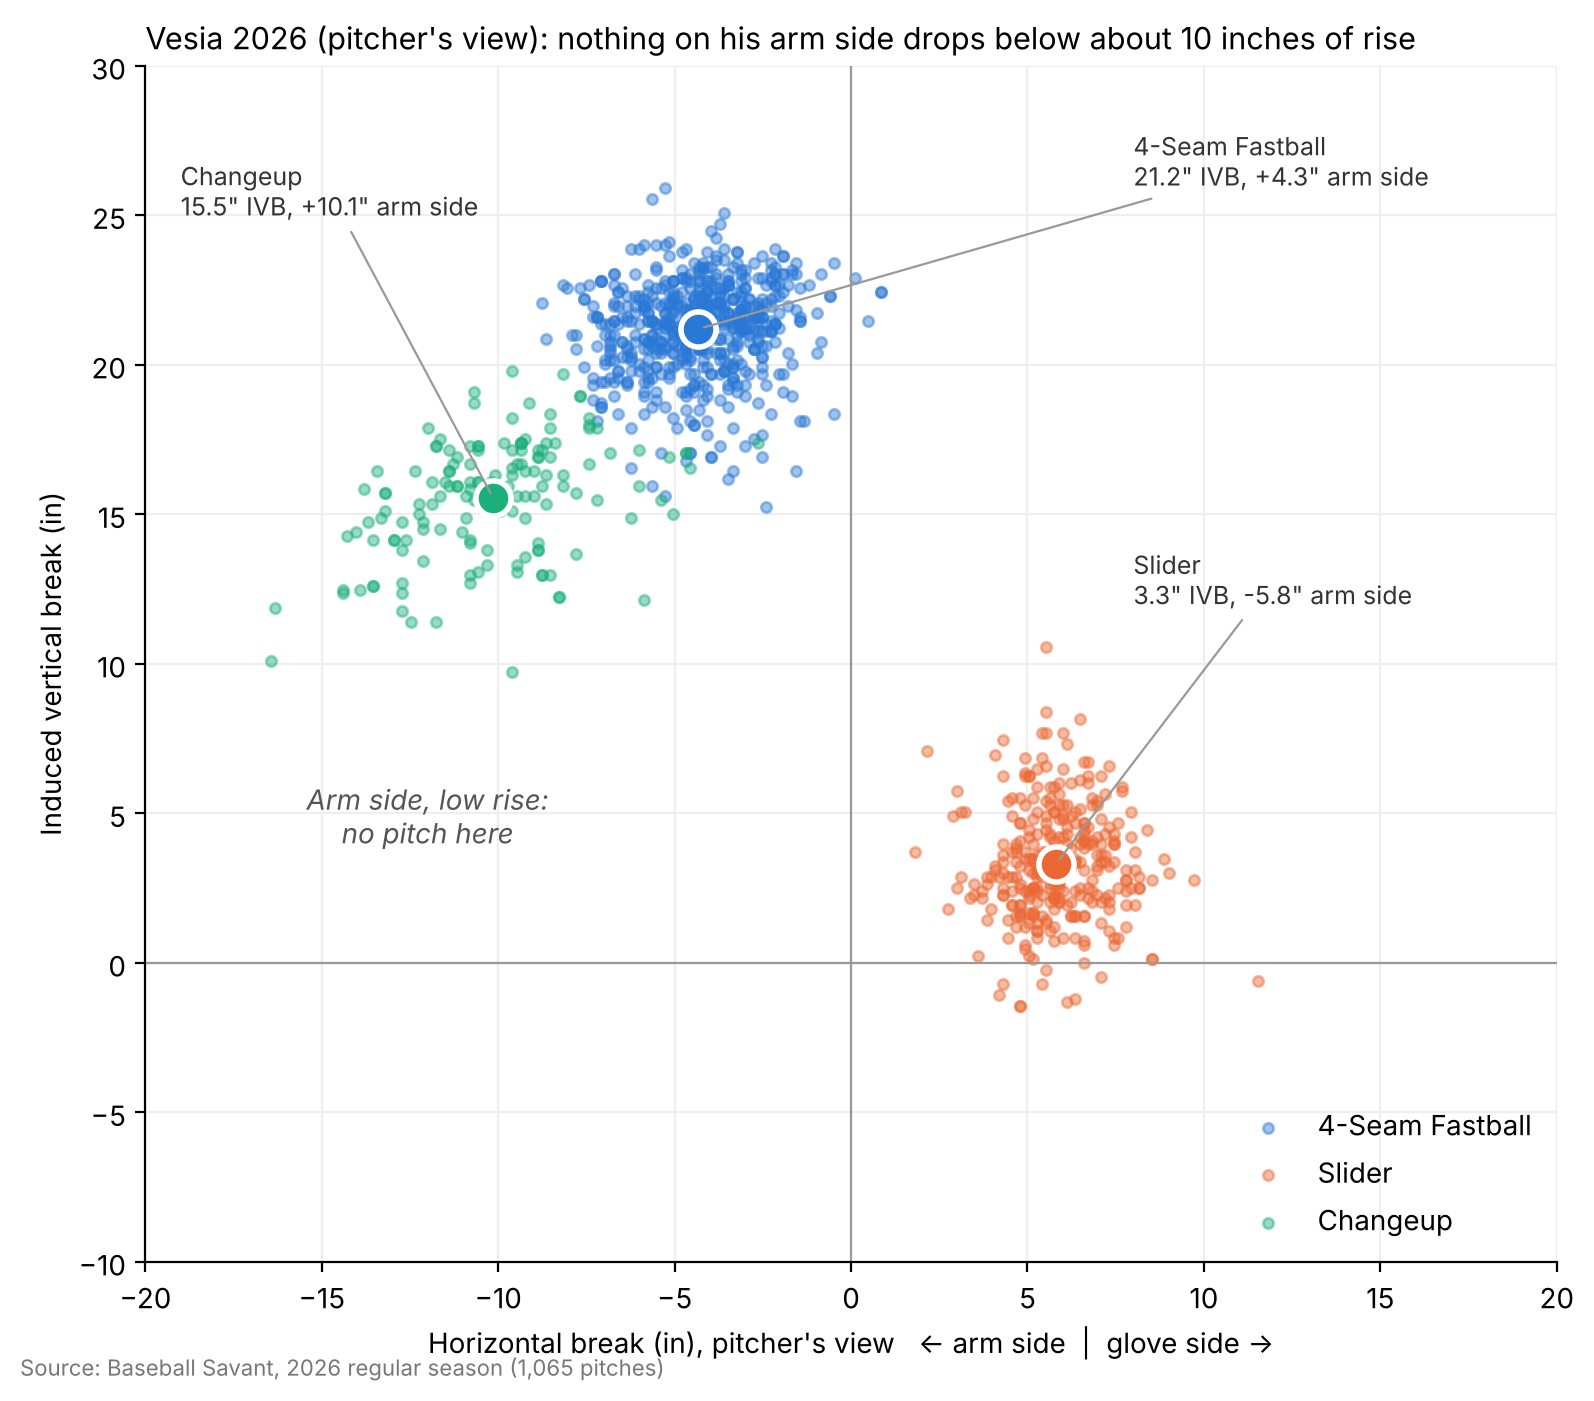

In [19]:
# STEP 3.6 — Movement chart (pitcher's view)
vesia_clean["hb_pitcher_view"] = -vesia_clean["pfx_x"] * 12

colors = {"4-Seam Fastball": "#2a78d6", "Slider": "#eb6834", "Changeup": "#1baf7a"}
label_pos = {"4-Seam Fastball": (8, 26), "Slider": (8, 12), "Changeup": (-19, 25)}

fig, ax = plt.subplots(figsize=(8, 7))

for pitch, color in colors.items():
    p = vesia_clean[vesia_clean["pitch_name"] == pitch]
    ax.scatter(p["hb_pitcher_view"], p["ivb"], s=14, color=color, alpha=0.45, label=pitch)
    ax.scatter(p["hb_pitcher_view"].mean(), p["ivb"].mean(), s=160, color=color, edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(f'{pitch}\n{p["ivb"].mean():.1f}" IVB, {p["hb_arm"].mean():+.1f}" arm side',
                xy=(p["hb_pitcher_view"].mean(), p["ivb"].mean()), xytext=label_pos[pitch],
                fontsize=9, color="#333333", arrowprops=dict(arrowstyle="-", color="#999999", linewidth=0.8))

ax.axhline(0, color="#999999", linewidth=0.8)
ax.axvline(0, color="#999999", linewidth=0.8)
ax.text(-12, 4, "Arm side, low rise:\nno pitch here", ha="center", fontsize=10, color="#555555", style="italic")

ax.set_xlim(-20, 20)
ax.set_ylim(-10, 30)
ax.set_xlabel("Horizontal break (in), pitcher's view   ← arm side  |  glove side →")
ax.set_ylabel("Induced vertical break (in)")
ax.set_title("Vesia 2026 (pitcher's view): nothing on his arm side drops below about 10 inches of rise", fontsize=11, loc="left")
ax.legend(loc="lower right", frameon=False)
ax.grid(color="#eeeeee")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.text(0.01, 0.01, "Source: Baseball Savant, 2026 regular season (1,065 pitches)", fontsize=8, color="#777777")

plt.tight_layout()
fig.savefig("../outputs/charts/step03_movement_chart.png", dpi=150)
plt.show()

**What I found:** Seen from behind the pitcher, Vesia's three pitches form three separate clusters. His four-seamer sits high, with about 21 inches of rise and a little arm-side run. His changeup sits further to his arm side but still high, at about 15.5 inches of rise, overlapping the lower edge of the fastball cluster. His slider sits low and to his glove side. The area on his arm side below about 10 inches of rise is empty: nothing in his arsenal runs toward his arm side while dropping well below the fastball. That is the space a splitter would fill.

### Working hypothesis

Vesia's changeup behaves like a soft fastball. It keeps an average of 15.5 inches of induced vertical break, and some changeups reach 17.4 inches, more than a typical big-league four-seamer. Combined with an arm angle about 6.5 (degrees) lower than his fastball, that means hitters face a pitch that neither drops away from the fastball nor hides behind it.

My hypothesis is that a vertical splitter, thrown from his fastball slot, would serve him better. Released from the same window as his four-seamer, it would travel on the same early path and then finish well below it, while his fastball keeps riding through the top of the zone. This is the same principle behind Yoshinobu Yamamoto's fastball-and-splitter pairing, although Yamamoto throws from a much lower arm slot, so I use Trey Yesavage, whose slot is close to Vesia's, as the main comparison. The steps that follow test this idea.

**What I found in Step 3:** Vesia's arsenal is built on an elite riding four-seamer: 92.1 mph, 21.2 inches of rise, 97.8% spin efficiency and a flat −4.2 (degrees) approach angle, thrown 56.4% of the time. His slider is a gyro slider, at 84.4 mph with only 44.9% spin efficiency and 3.3 inches of rise, and it misses bats on 38.6% of swings. His changeup gets the best results on paper, with a 44.0% whiff rate and a .231 xwOBA, but on only 75 swings, and its shape works against it: 99.1% efficient backspin keeps it at 15.5 inches of rise, just 5.7 inches below the fastball, and it leaves his hand from a 62.5 (degrees) arm angle, 6.5 (degrees) lower than his fastball. On the movement chart, the arm side below about 10 inches of rise is empty.

<a id="step-4"></a>
## Step 4: How separated is the changeup from the fastball?

A secondary pitch works when hitters can't tell it apart from the fastball early, but it ends up somewhere very different. That difference is called separation, and it can come from speed, from movement, or from both. Step 3 showed that Vesia's changeup sits close to his four-seamer on the movement chart. In this step I measure exactly how close, by subtracting the four-seamer's averages from the changeup's for every metric in the shape table. I do the same for the slider, which gives a reference for what strong separation looks like in his own arsenal.

### 4.1 The gap between each pitch and the four-seamer

Here I subtract the four-seamer's row of the shape table from the changeup's row, and then from the slider's row. Each number in the result is a gap: how much slower, how much less spin, how many inches less rise, and so on. A negative gap means the secondary pitch has less of that quantity than the fastball. For induced vertical break and approach angle, the bigger the negative gap, the more the pitch drops away from the fastball's path.

In [20]:
# STEP 4.1 — Gaps from the four-seamer
ch_gap = shape.loc["Changeup"] - shape.loc["4-Seam Fastball"]
sl_gap = shape.loc["Slider"] - shape.loc["4-Seam Fastball"]
gaps = pd.DataFrame({"changeup_vs_ff": ch_gap, "slider_vs_ff": sl_gap}).round(1)
gaps

,changeup_vs_ff,slider_vs_ff
release_speed,-9.3,-7.7
release_spin_rate,-625.9,-134.4
spin_axis,-31.6,49.1
ivb,-5.7,-17.9
hb_arm,5.8,-10.1
arm_angle,-6.5,4.8
vaa,-2.3,-3.4
active_spin,1.3,-52.9


**What I found:** The changeup separates from the four-seamer mostly through speed, not movement. It is 9.3 mph slower and spins 626 rpm less, but it gives up only 5.7 inches of rise and enters the zone just 2.3 (degrees) steeper. The slider shows what strong separation looks like in his own arsenal: 17.9 inches less rise, 10.1 inches of break the other way and a 3.4 (degrees) steeper angle. The changeup also leaves his hand from an arm angle 6.5 (degrees) lower than the fastball, while the slider comes out about 5 (degrees) higher, so neither secondary pitch shares the fastball's release slot.

### 4.2 How close does the changeup get to the fastball's ride?

Averages can hide how two pitches overlap, so here I compare them pitch by pitch. I use two lines for the bottom of Vesia's fastball range: his single lowest-riding four-seamer, and the level that only his bottom 10% of four-seamers fall below. Then I count how many changeups rise at least that much. Using both lines matters, because a count based on one unusual fastball can make the overlap look much bigger than it really is.

In [21]:
# STEP 4.2 — Changeups inside the fastball's ride range
ff_ivb = vesia_clean[vesia_clean["pitch_name"] == "4-Seam Fastball"]["ivb"]
ch_ivb = vesia_clean[vesia_clean["pitch_name"] == "Changeup"]["ivb"]
ff_floor = ff_ivb.min()
ch_overlap = (ch_ivb >= ff_floor).sum()
print(f"Lowest four-seamer IVB: {ff_floor:.1f} in. Changeups at or above it: {ch_overlap} of {len(ch_ivb)} ({ch_overlap / len(ch_ivb):.1%}).")
ff_p10 = ff_ivb.quantile(0.10)
print(f"Bottom 10% of four-seamer IVB: {ff_p10:.1f} in. Changeups at or above it: {(ch_ivb >= ff_p10).sum()} of {len(ch_ivb)} ({(ch_ivb >= ff_p10).mean():.1%}).")

Lowest four-seamer IVB: 15.2 in. Changeups at or above it: 93 of 149 (62.4%).
Bottom 10% of four-seamer IVB: 19.2 in. Changeups at or above it: 2 of 149 (1.3%).


**What I found:** 93 of his 149 changeups (62.4%) ride at least as much as his single lowest-riding four-seamer, at 15.2 inches. Against a more typical fastball, though, the overlap almost disappears: only 2 changeups (1.3%) reach the bottom 10% of his fastballs, at 19.2 inches. The changeup doesn't ride like a normal Vesia fastball; it sits consistently about 5 to 6 inches below it. That gap is real but small, a third of the 17.9 inches his slider creates, and that is the separation a splitter would widen.

**What I found in Step 4:** Vesia's changeup separates from his four-seamer mainly through speed. It is 9.3 mph slower, but it keeps most of the fastball's vertical movement: only 5.7 inches less rise and a 2.3 (degrees) steeper approach angle. His slider shows what strong separation looks like in his own arsenal, with 17.9 inches less rise and 10.1 inches of break in the opposite direction. The changeup also comes from an arm angle 6.5 (degrees) lower than his fastball. A splitter would aim to keep the speed gap, add about 8 to 10 more inches of vertical separation, and come out of the same slot as the fastball.

<a id="step-5"></a>
## Step 5: Does he show the same slot on every pitch?

Hitters start reading a pitch the moment it leaves the hand. If a pitcher releases his changeup from a different arm angle or a different spot than his fastball, a good hitter can pick it up early, and the pitch loses much of its value no matter how it moves. Step 4 showed that Vesia's changeup comes from an arm angle 6.5 (degrees) lower than his four-seamer. In this step I check whether that difference is a real, consistent pattern or just noise in the averages, and whether it holds against both left- and right-handed hitters.

### 5.1 Arm angle and release point by pitch

For each pitch type I calculate the average arm angle and its standard deviation, along with the average release height, release side and extension. The standard deviation measures how much the arm angle normally varies from one throw to the next. If the gap between two pitches is much larger than that normal variation, the difference is a consistent habit, not random noise.

In [22]:
# STEP 5.1 — Slot by pitch type
slot = vesia_clean.groupby("pitch_name").agg(arm_mean=("arm_angle", "mean"),
                                             arm_sd=("arm_angle", "std"),
                                             rel_side=("release_pos_x", "mean"),
                                             rel_height=("release_pos_z", "mean"),
                                             extension=("release_extension", "mean"))
slot.reindex(usage.index).round(2)

,arm_mean,arm_sd,rel_side,rel_height,extension
pitch_name,,,,,
4-Seam Fastball,69.03,2.75,0.13,5.96,6.42
Slider,73.85,2.52,-0.03,6.15,6.34
Changeup,62.46,2.80,0.54,5.92,6.45


**How to read this table:** `arm_mean` is the average arm angle for each pitch, in degrees: how high his arm is at release, where 90 (degrees) would be straight over the top and 0 (degrees) fully sidearm. `arm_sd` is the standard deviation of that arm angle, which measures how much it normally varies from one throw of the same pitch to the next. `rel_side` and `rel_height` show where the ball leaves his hand, in feet: side-to-side from the center of the rubber (from the catcher's view, so for a lefty a larger number means further toward his arm side) and height above the ground. `extension` is how far in front of the rubber he lets go of the ball, in feet.

**What I found:** Vesia releases his changeup from an arm angle of 62.5 (degrees), 6.6 (degrees) lower than his four-seamer at 69.0 (degrees). That gap is about 2.4 times the normal throw-to-throw variation of either pitch (about 2.8 (degrees)), so it is a consistent habit, not noise. The release point shows where the difference comes from: the changeup leaves his hand at almost the same height as the fastball (5.92 vs 5.96 feet, half an inch lower) but about 5 inches further out toward his arm side (0.54 vs 0.13 feet). He drops his arm angle by moving his hand out to the side, not down. The slider goes the other way, released 4.8 (degrees) higher and about 2 inches higher. Extension is nearly identical across all three pitches.

### 5.2 Does the slot change against left- and right-handed hitters?

Vesia throws almost all of his changeups to right-handed hitters (144 of 149), while his slider is used more against left-handers. A pitcher sometimes adjusts his release depending on who is at the plate, so a gap in the averages could partly reflect who he's facing rather than the pitch itself. Here I build a table of average arm angle with pitch types as rows and batter side as columns, plus a second table counting how many pitches sit in each cell.

In [23]:
# STEP 5.2 — Arm angle by pitch and batter side
arm_by_side = vesia_clean.pivot_table(index="pitch_name", columns="stand", values="arm_angle", aggfunc="mean").round(1)
n_by_side = vesia_clean.pivot_table(index="pitch_name", columns="stand", values="arm_angle", aggfunc="count")
display(arm_by_side.reindex(usage.index))
display(n_by_side.reindex(usage.index))

stand,L,R
pitch_name,,
4-Seam Fastball,69.1,69.0
Slider,73.8,73.9
Changeup,60.9,62.5


stand,L,R
pitch_name,,
4-Seam Fastball,269,332
Slider,197,118
Changeup,5,144


**What I found:** The slot difference holds no matter who is batting. Against right-handed hitters, who see 144 of his 149 changeups, his four-seamer comes out at 69.0 (degrees) and his changeup at 62.5 (degrees), the same 6.5 (degrees) gap as in the overall averages. Against left-handers the fastball sits at 69.1 (degrees), almost identical. The changeup's 60.9 (degrees) against left-handers comes from only 5 pitches, too few to read. The slider is just as stable, at 73.8 (degrees) and 73.9 (degrees). The lower changeup slot is part of the pitch itself, not a reaction to the hitter.

### 5.3 The arm angle of every pitch

The tables give averages; this chart shows every pitch. For each pitch type, I draw the distribution of its arm angles as an outline: the higher the line at a given angle, the more of that pitch he released there. A dashed line marks each pitch's average.

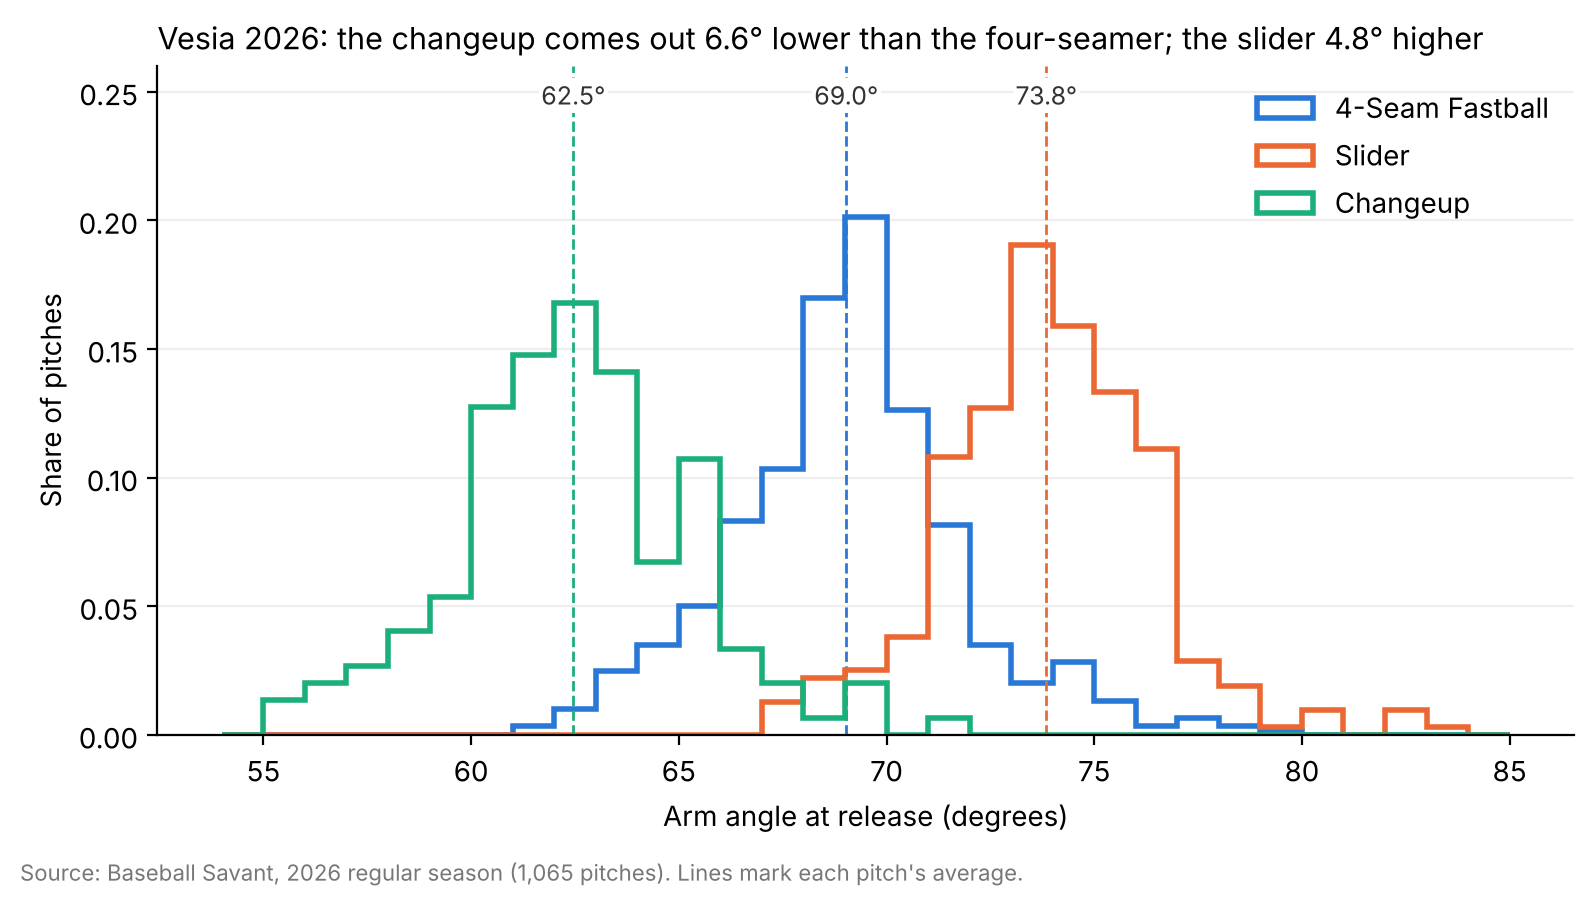

In [24]:
# STEP 5.3 — Arm angle distribution by pitch
fig, ax = plt.subplots(figsize=(8, 4.5))
bins = range(54, 86, 1)

for pitch, color in colors.items():
    p = vesia_clean[vesia_clean["pitch_name"] == pitch]
    ax.hist(p["arm_angle"], bins=bins, density=True, histtype="step", linewidth=2, color=color, label=pitch)
    ax.axvline(p["arm_angle"].mean(), color=color, linewidth=1, linestyle="--")
    ax.text(p["arm_angle"].mean(), 0.245, f'{p["arm_angle"].mean():.1f}°', color="#333333", ha="center",
            fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1))

ax.set_ylim(0, 0.26)
ax.set_xlabel("Arm angle at release (degrees)")
ax.set_ylabel("Share of pitches")
ax.set_title("Vesia 2026: the changeup comes out 6.6° lower than the four-seamer; the slider 4.8° higher", fontsize=11, loc="left")
ax.legend(loc="upper right", frameon=False)
ax.grid(axis="y", color="#eeeeee")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.text(0.01, 0.01, "Source: Baseball Savant, 2026 regular season (1,065 pitches). Lines mark each pitch's average.", fontsize=8, color="#777777")

plt.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("../outputs/charts/step05_arm_angle_by_pitch.png", dpi=150)
plt.show()

**What I found:** Each of Vesia's pitches comes from its own arm-angle window. His changeup averages 62.5 (degrees), his four-seamer 69.0 (degrees) and his slider 73.8 (degrees), and the three distributions peak in clearly different places, with the changeup and four-seamer overlapping only at their edges. A hitter who learns that difference can recognize the changeup at release, before it shows any movement.

**What I found in Step 5:** Vesia does not show the same slot on every pitch. His changeup comes out at a 62.5 (degrees) arm angle, 6.6 (degrees) below his four-seamer, a gap about 2.4 times the normal throw-to-throw variation of either pitch, and it holds against right-handed hitters, who see almost all of his changeups. The difference comes mostly from release side, not height: the changeup leaves his hand about 5 inches further toward his arm side, at almost the same height. That gives the splitter a clear requirement: it must come from the fastball's slot, within about 2 (degrees) of arm angle and 1 to 2 inches of release side, so that hitters can't separate it from the four-seamer until it starts to drop.

<a id="step-6"></a>
## Step 6: What does a good MLB splitter look like?

Before designing a splitter for Vesia, I need to know what splitters look like across the league and which of their traits go with success. Without that benchmark, any target I set for velocity, spin or movement would be a guess. This step uses Baseball Savant's 2026 table of every pitcher who threw a splitter, keeping only those with at least 100, so each pitcher's averages rest on a meaningful sample.

I first describe the typical MLB splitter, then look at the pitchers whose arm slot is closest to Vesia's, at 50 (degrees) or higher, and finally check which traits go together with a higher whiff rate and a lower expected wOBA, keeping in mind that a relationship across pitchers doesn't prove that one trait causes the other.

### 6.1 Load the league splitters

I load the league splitter table and keep only the pitchers who threw at least 100 splitters in 2026. Then I convert the two movement columns from feet to inches, so they use the same units as Vesia's data. In this table, Savant already measures horizontal break toward each pitcher's arm side, so it matches the `hb_arm` column I built for Vesia without any sign changes.

In [25]:
# STEP 6.1 — League splitters with 100+ pitches
lb_fs = pd.read_csv("../data/raw/lb_splitters_2026.csv")
fs = lb_fs[lb_fs["pitches"] >= 100].copy()
fs["ivb"] = fs["api_break_z_induced"] * 12
fs["hb_arm"] = fs["api_break_x_arm"] * 12
print(len(fs))
fs[["player_name", "pitches", "velocity", "ivb", "hb_arm", "arm_angle"]].head()

59


,player_name,pitches,velocity,ivb,hb_arm,arm_angle
0,"Gausman, Kevin",1177,84.0,4.32,13.92,34.9
1,"Imanaga, Shota",970,82.8,5.64,11.64,38.3
2,"Eovaldi, Nathan",831,88.4,0.96,12.96,37.2
3,"Yamamoto, Yoshinobu",728,91.5,1.80,11.88,39.1
4,"Mahle, Tyler",713,86.3,4.56,13.44,37.6


**What I found:** 59 MLB pitchers threw at least 100 splitters in 2026, from Kevin Gausman with 1,177 to pitchers just above the cutoff. Converted to inches, the splitters at the top of the list show the classic shape of the pitch: very little rise (1 to 6 inches) and a lot of arm-side run (12 to 14 inches). Their arm angles sit mostly in the mid-to-high 30s, far below Vesia's 69 (degrees), which is why the next cells look at high-slot splitters separately.

### 6.2 How much slower than the fastball?

A splitter's speed only matters relative to the pitcher's own fastball: an 86 mph splitter plays very differently behind a 98 mph fastball than behind a 90 mph one. The splitter table doesn't include each pitcher's four-seamer velocity, so I bring it in from the pitch arsenal leaderboard, matching the two tables by each pitcher's Statcast ID. Then I calculate the velocity gap, splitter minus four-seamer, for every pitcher.

In [26]:
# STEP 6.2 — Velocity gap from the four-seamer
lb_arsenal = pd.read_csv("../data/raw/lb_pitch_arsenals_2026.csv")
fs = fs.merge(lb_arsenal[["pitcher", "ff_avg_speed"]], left_on="player_id", right_on="pitcher", how="left")
fs["velo_gap"] = fs["velocity"] - fs["ff_avg_speed"]
print(fs["velo_gap"].notna().sum())
fs[["player_name", "velocity", "ff_avg_speed", "velo_gap"]].head()

47


,player_name,velocity,ff_avg_speed,velo_gap
0,"Gausman, Kevin",84.0,93.8,-9.8
1,"Imanaga, Shota",82.8,91.6,-8.8
2,"Eovaldi, Nathan",88.4,94.4,-6.0
3,"Yamamoto, Yoshinobu",91.5,96.1,-4.6
4,"Mahle, Tyler",86.3,92.8,-6.5


**What I found:** 47 of the 59 splitter pitchers also throw a four-seamer, so I can measure how much slower their splitter is. The gap varies a lot even among the top names: Yoshinobu Yamamoto's splitter is only 4.6 mph slower than his fastball, while Kevin Gausman's is 9.8 mph slower. The other 12 pitchers lead with a sinker instead of a four-seamer; they stay in the table for every other measure. For reference, Vesia's current changeup is 9.3 mph slower than his four-seamer, near the large-gap end of this range.

### 6.3 The typical MLB splitter

Here I summarize the league's splitters with three numbers per measure: the 25th percentile, the median and the 75th percentile. The median is the middle splitter, and the 25th and 75th percentiles mark the range that holds the middle half of the league. A target for Vesia's splitter that falls inside that range is a realistic, proven shape.

In [27]:
# STEP 6.3 — League splitter benchmarks
bench_cols = ["velocity", "spin_rate", "ivb", "hb_arm", "arm_angle", "velo_gap", "swing_miss_percent", "xwoba"]
fs_bench = fs[bench_cols].quantile([0.25, 0.5, 0.75]).T.round(3)
fs_bench

,0.25,0.50,0.75
velocity,84.050,86.100,88.300
spin_rate,1120.500,1439.000,1632.500
ivb,1.320,2.280,5.340
hb_arm,9.180,11.280,13.440
arm_angle,35.200,39.300,45.150
velo_gap,-9.850,-8.500,-6.250
swing_miss_percent,29.350,33.300,39.100
xwoba,0.223,0.259,0.288


**What I found:** The typical MLB splitter in 2026 is thrown at 86.1 mph, spins at 1,439 rpm and is 8.5 mph slower than the pitcher's four-seamer. It has almost no rise, a median of 2.3 inches of induced vertical break, with the middle half of the league between 1.3 and 5.3 inches, and it runs 11.3 inches toward the arm side. It gets swings and misses on 33.3% of swings and allows a .259 expected wOBA. Vesia's changeup, with 15.5 inches of rise, sits about three times above even the 75th percentile for a splitter.

### 6.4 Splitters from a high arm slot

Vesia throws from a 69 (degrees) arm angle, far above the typical splitter pitcher's 39 (degrees). A splitter released from a higher slot tends to spin and move differently, so the league-wide medians may not describe what his splitter would realistically look like. Here I split the 59 pitchers into two groups, those with an arm angle of 50 (degrees) or higher and everyone else, and compare the median of each measure. Then I list the high-slot pitchers themselves, from highest slot to lowest.

In [28]:
# STEP 6.4 — High-slot splitters vs the rest
fs["slot_group"] = np.where(fs["arm_angle"] >= 50, "High (50°+)", "Below 50°")
print(fs["slot_group"].value_counts())
slot_compare = fs.groupby("slot_group")[bench_cols].median().T.round(3)
display(slot_compare)
high_slot = fs[fs["arm_angle"] >= 50][["player_name", "pitches", "velocity", "spin_rate", "ivb", "hb_arm", "arm_angle",
                                        "velo_gap", "swing_miss_percent", "xwoba"]].sort_values("arm_angle", ascending=False).round(3)
display(high_slot)

slot_group
Below 50°      49
High (50°+)    10
Name: count, dtype: int64


slot_group,Below 50°,High (50°+)
velocity,86.300,83.200
spin_rate,1462.000,1255.000
ivb,2.160,4.920
hb_arm,11.520,8.940
arm_angle,38.300,54.500
velo_gap,-8.300,-8.700
swing_miss_percent,32.800,38.100
xwoba,0.266,0.233


,player_name,pitches,velocity,spin_rate,ivb,hb_arm,arm_angle,velo_gap,swing_miss_percent,xwoba
42,"Estrada, Jeremiah",164,82.1,1295,7.68,12.36,67.1,NaN,49.3,0.203
15,"Yesavage, Trey",470,82.9,1392,6.72,11.64,66.0,-11.3,38.8,0.248
37,"Myers, Tobias",212,80.2,1439,8.40,8.88,63.6,-12.3,36.1,0.227
47,"Ralston, Jack",159,82.5,905,1.20,9.48,60.6,NaN,23.1,0.301
38,"Kikuchi, Yusei",208,86.6,1592,8.40,9.00,54.7,-8.9,33.0,0.315
6,"Bradley, Taj",587,91.5,1742,6.12,10.68,54.3,-5.7,37.4,0.239
31,"Matsui, Yuki",281,83.5,1174,3.72,8.52,54.2,-8.5,47.1,0.219
57,"Chapman, Aroldis",103,90.2,1215,3.00,5.64,53.0,-6.7,41.3,0.155
11,"Cruz, Fernando",484,80.0,724,1.44,4.20,50.6,-13.2,52.0,0.214
5,"Sasaki, Roki",613,90.2,916,1.08,7.08,50.2,-7.7,36.5,0.257


**What I found:** Only 10 of the 59 splitter pitchers throw from an arm angle of 50 (degrees) or higher, and their splitters have a different shape from the rest of the league. The median high-slot splitter keeps more rise (4.9 vs 2.2 inches), runs less to the arm side (8.9 vs 11.5 inches), spins less (1,255 vs 1,462 rpm) and is thrown a little slower (83.2 vs 86.3 mph), with a similar 8.7 mph gap from the four-seamer. It also performs better: a 38.1% whiff rate against 32.8%, and a .233 expected wOBA against .266. With only 10 pitchers, that difference is a promising sign rather than proof. Among these 10, rise depends heavily on spin: the three pitchers with slots closest to Vesia's (63–67 (degrees)) keep 6.7 to 8.4 inches of rise at 1,300 to 1,450 rpm. Trey Yesavage, at 66.0 (degrees), has the closest slot to Vesia's among pitchers with a full season of splitters.

### 6.5 Which traits go with better splitters?

For each measure, I calculate its correlation with whiff rate and with expected wOBA across the 59 pitchers. A correlation is a number between −1 and 1 that shows how closely two measures move together: close to 1, they rise together; close to −1, one rises as the other falls; close to 0, they're unrelated. For whiff rate, higher is better for the pitcher; for expected wOBA, lower is better.

In [29]:
# STEP 6.5 — Correlation of each trait with results
corr = fs[bench_cols].corr()
results_corr = corr[["swing_miss_percent", "xwoba"]].drop(["swing_miss_percent", "xwoba"]).round(2)
results_corr.columns = ["corr_with_whiff_pct", "corr_with_xwoba"]
results_corr

,corr_with_whiff_pct,corr_with_xwoba
velocity,-0.25,0.11
spin_rate,-0.40,0.35
ivb,-0.01,0.02
hb_arm,-0.34,0.45
arm_angle,0.18,-0.23
velo_gap,-0.52,0.42


**What I found:** Across the 59 splitter pitchers, the trait most closely tied to good results is the speed gap from the four-seamer. Splitters that are slower relative to the pitcher's fastball get more whiffs (correlation −0.52) and allow a lower expected wOBA (0.42 with the gap). Lower spin (−0.40 with whiff rate) and less arm-side run (−0.34) also go with better results, and a higher arm slot shows a small positive link (0.18). The splitter's induced vertical break on its own shows no relationship with whiffs (−0.01). That does not mean drop is unimportant: what matters for a hitter is how far a splitter falls below the pitcher's own fastball, and this table does not include each pitcher's fastball rise, so it cannot measure that gap. These are relationships across pitchers, not proof of cause.

**What I found in Step 6:** The typical MLB splitter in 2026 is thrown at 86.1 mph, 8.5 mph slower than the pitcher's four-seamer, spins at 1,439 rpm, keeps only 2.3 inches of rise and runs 11.3 inches to the arm side. The 10 pitchers who throw it from an arm slot of 50 (degrees) or higher keep more rise (4.9 inches), run less (8.9 inches), spin less (1,255 rpm) and get better results, with a 38.1% whiff rate and a .233 expected wOBA. Across the league, the traits most tied to success are a large speed gap from the fastball, low spin and moderate arm-side run. Trey Yesavage, with a 66.0 (degrees) slot, is the closest full-season model for Vesia: an 82.9 mph splitter, 11.3 mph slower than his four-seamer, with 6.7 inches of rise and a 38.8% whiff rate.

<a id="step-7"></a>
## Step 7: What exactly should Vesia's splitter be?

The previous steps define the problem and the benchmarks. Vesia's changeup keeps 15.5 inches of rise, only 5.7 inches below his four-seamer, and it comes from an arm angle 6.6 (degrees) lower and about 5 inches further toward his arm side. Across the league, splitters keep about 2 inches of rise, and the ones thrown from high arm slots keep about 5. In this step I turn those findings into a specification: a target for each measure and the reason behind it. The targets describe a pitch Vesia doesn't throw yet, so they are goals to test in bullpens, not predictions.

### Splitter specification

The first target is velocity. Vesia's splitter should be thrown at 82.5 to 84 mph, about the same speed as his current changeup (82.8 mph) and 8 to 9.5 mph slower than his 92.1 mph four-seamer. Across the league, the speed gap between a splitter and the pitcher's fastball is the trait most closely tied to whiffs (a correlation of −0.52), so keeping a large gap is a priority.

The second target is spin, which is what controls how much the pitch drops. His changeup spins at 1,887 rpm with almost perfect efficiency, which is why it holds its height. The splitter should spin at 1,250 to 1,450 rpm. Among splitters thrown from high arm slots, spin and rise move closely together (a correlation of 0.84), and this range matches what Jeremiah Estrada, Trey Yesavage and Tobias Myers throw from slots similar to Vesia's. It is a large but realistic cut for a pitcher whose spin is naturally high and efficient.

With that spin, the splitter should keep 5 to 8 inches of induced vertical break, compared with 15.5 inches on his changeup. That would put it 13 to 16 inches below his four-seamer, more than twice the changeup's 5.7-inch gap. The three pitchers whose arm slots are closest to his, between 63 (degrees) and 67 (degrees), keep 6.7 to 8.4 inches of rise on their splitters, so the target sits within what his arm can realistically produce.

Sideways, the splitter should run 7 to 11 inches toward his arm side, close to his changeup's 10.1 inches and to the high-slot median of 8.9. More run is not better here: across the league, splitters with more arm-side movement allow a higher expected wOBA (a correlation of 0.45).

The release targets matter as much as the movement. The splitter should leave his hand from an arm angle of 67 (degrees) to 71 (degrees), within 2 (degrees) of his four-seamer's 69.0 (degrees), instead of the changeup's 62.5 (degrees). It should also come from within 1 to 2 inches of the fastball's release side, since the changeup's tell is the 5 inches it drifts toward his arm side. Finally, the pitch has to be repeatable: its rise should vary by no more than about 2.5 inches from throw to throw, similar to the 2.0 inches his changeup varies now.

In games, the splitter will be judged a success if it reaches a whiff rate at or above the high-slot median of 38.1% and holds hitters to an expected wOBA at or below .233. Its role is to replace the changeup against right-handed hitters, who saw 144 of his 149 changeups, and to be tested as a two-strike pitch against left-handers.

### 7.1 Store the targets

To draw the splitter's target zone on the movement chart in Step 8, I store the targets as numbers in the notebook. I also calculate how far below his four-seamer the target rise would put the splitter, to confirm it creates the vertical separation the changeup lacks.

In [30]:
# STEP 7.1 — Splitter targets
fs_target = {"ivb": (5, 8), "hb_arm": (7, 11), "velo": (82.5, 84.0), "spin": (1250, 1450)}
ff_ivb_mean = shape.loc["4-Seam Fastball", "ivb"]
print(f"Target splitter sits {ff_ivb_mean - fs_target['ivb'][1]:.1f} to {ff_ivb_mean - fs_target['ivb'][0]:.1f} in below the four-seamer (changeup now: 5.7 in).")

Target splitter sits 13.2 to 16.2 in below the four-seamer (changeup now: 5.7 in).


**What I found in Step 7:** Vesia's splitter should be thrown at 82.5 to 84 mph, 8 to 9.5 mph below his four-seamer, with 1,250 to 1,450 rpm of spin, 5 to 8 inches of rise and 7 to 11 inches of arm-side run, released from the same slot as his fastball: within 2 (degrees) of its 69 (degrees) arm angle and 1 to 2 inches of its release side. That pitch would finish 13 to 16 inches below his four-seamer, more than twice the changeup's 5.7, while leaving his hand from the same spot. Every target sits inside what MLB high-slot pitchers already throw, which makes it a realistic goal for bullpen work rather than a hypothetical pitch.

<a id="step-8"></a>
## Step 8: How would his arsenal look with a splitter?

This step brings the specification back to the picture that started the project. I redraw the movement chart from Step 3, with every pitch Vesia threw in 2026, and add the splitter's target zone from Step 7: 5 to 8 inches of rise and 7 to 11 inches of arm-side run. An arrow from the changeup's average to the target zone shows the change I am proposing: the same arm-side direction with about 8 to 10 inches less rise. The zone is a target, not thrown pitches, and the chart says so.

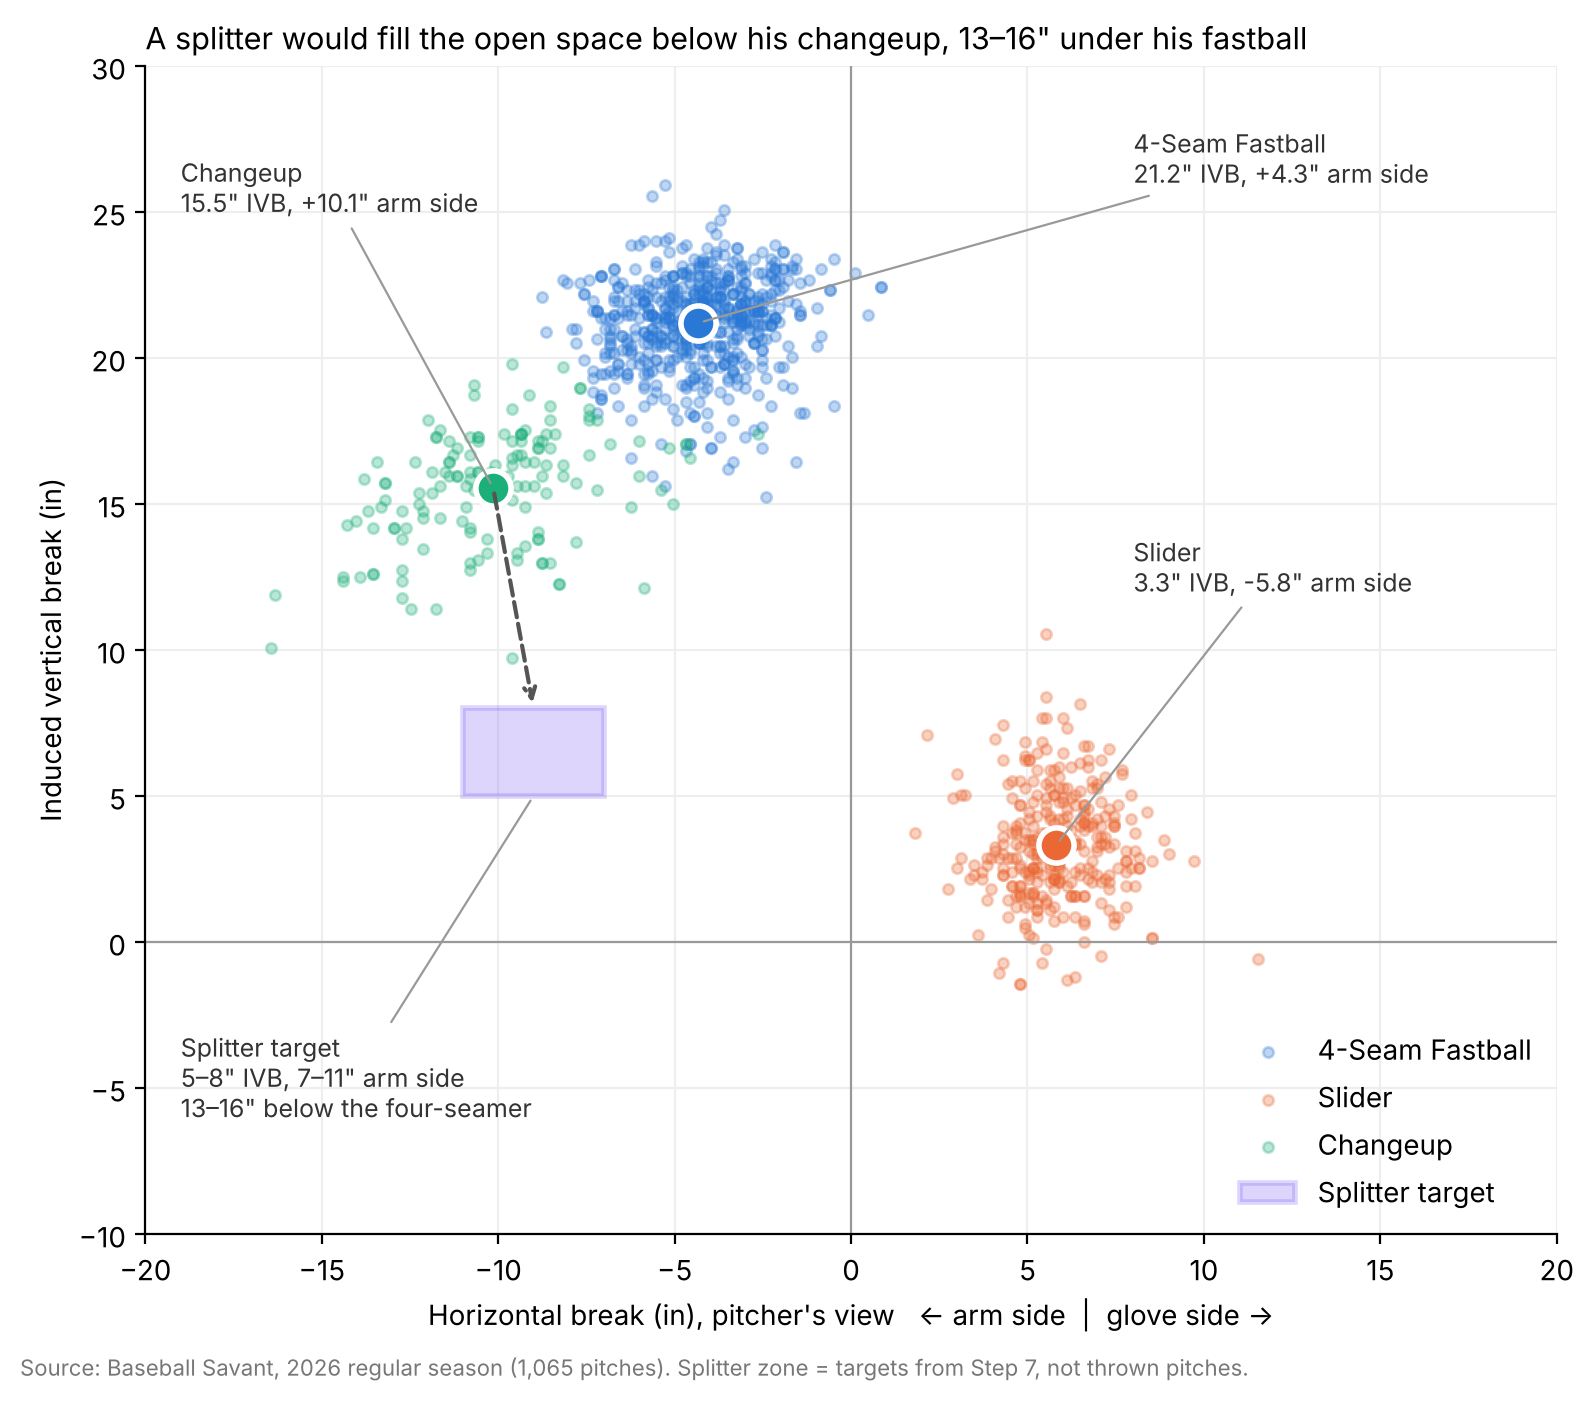

In [31]:
# STEP 8.1 — Arsenal with the splitter target zone
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(8, 7))

for pitch, color in colors.items():
    p = vesia_clean[vesia_clean["pitch_name"] == pitch]
    ax.scatter(p["hb_pitcher_view"], p["ivb"], s=14, color=color, alpha=0.3, label=pitch)
    ax.scatter(p["hb_pitcher_view"].mean(), p["ivb"].mean(), s=160, color=color, edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(f'{pitch}\n{p["ivb"].mean():.1f}" IVB, {p["hb_arm"].mean():+.1f}" arm side',
                xy=(p["hb_pitcher_view"].mean(), p["ivb"].mean()), xytext=label_pos[pitch],
                fontsize=9, color="#333333", arrowprops=dict(arrowstyle="-", color="#999999", linewidth=0.8))

x_left = -fs_target["hb_arm"][1]
width = fs_target["hb_arm"][1] - fs_target["hb_arm"][0]
y_bottom = fs_target["ivb"][0]
height = fs_target["ivb"][1] - fs_target["ivb"][0]

ax.add_patch(Rectangle((x_left, y_bottom), width, height, facecolor="#7a5af5", alpha=0.25,
                       edgecolor="#7a5af5", linewidth=2, zorder=2, label="Splitter target"))
ax.annotate("Splitter target\n5–8\" IVB, 7–11\" arm side\n13–16\" below the four-seamer",
            xy=(x_left + width / 2, y_bottom), xytext=(-19, -6), fontsize=9, color="#333333",
            arrowprops=dict(arrowstyle="-", color="#999999", linewidth=0.8))

ch = vesia_clean[vesia_clean["pitch_name"] == "Changeup"]
ax.annotate("", xy=(x_left + width / 2, y_bottom + height),
            xytext=(ch["hb_pitcher_view"].mean(), ch["ivb"].mean()),
            arrowprops=dict(arrowstyle="->", color="#555555", linewidth=1.5, linestyle="--"))

ax.axhline(0, color="#999999", linewidth=0.8)
ax.axvline(0, color="#999999", linewidth=0.8)
ax.set_xlim(-20, 20)
ax.set_ylim(-10, 30)
ax.set_xlabel("Horizontal break (in), pitcher's view   ← arm side  |  glove side →")
ax.set_ylabel("Induced vertical break (in)")
ax.set_title("A splitter would fill the open space below his changeup, 13–16\" under his fastball", fontsize=11, loc="left")
ax.legend(loc="lower right", frameon=False)
ax.grid(color="#eeeeee")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.text(0.01, 0.01, "Source: Baseball Savant, 2026 regular season (1,065 pitches). Splitter zone = targets from Step 7, not thrown pitches.",
         fontsize=8, color="#777777")

plt.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig("../outputs/charts/step08_arsenal_with_splitter.png", dpi=150)
plt.show()

**What I found in Step 8:** With the splitter target added, Vesia's movement chart fills its biggest gap. Today, everything on his arm side rides: the four-seamer at 21.2 inches and the changeup at 15.5. The splitter would keep the changeup's arm-side direction but drop it to 5 to 8 inches of rise, 13 to 16 inches below the fastball, in a space where he currently throws nothing. Combined with a release from the fastball's slot, it would give hitters two pitches that start the same way and finish more than a foot apart, plus a slider breaking the other way. The zone shows targets, not thrown pitches; Step 9 compares it with a real high-slot splitter.

<a id="step-9"></a>
## Step 9: How would Vesia benefit? The Yesavage comparison

The splitter in Step 7 is a target, so its value has to be estimated from someone who already throws it. Trey Yesavage is the best available model. His arm angle of 66 (degrees) is the closest to Vesia's 69 (degrees) among pitchers who threw a full season of splitters in 2026, and his fastball-and-splitter pairing is the same idea this project proposes. In this step I build Yesavage's profile with the same steps I used for Vesia, then put three versions of the fastball pairing side by side: Vesia's four-seamer and changeup today, the target splitter, and Yesavage's four-seamer and splitter as they performed in 2026.

Yesavage is a model, not a copy. He throws harder, releases the ball about a foot higher and pitched mostly from May to July, so his results show what the pairing can do, not exactly what Vesia would get.

### 9.1 Load Yesavage's pitches

I load Yesavage's 2026 pitch-by-pitch file, check its size and count his pitches by type. Unlike Vesia's file, it has no rows without a pitch type, so nothing needs to be removed, but I still use `.copy()` so I can add columns to it safely.

In [32]:
# STEP 9.1 — Load Yesavage's pitches
yesavage = pd.read_csv("../data/raw/yesavage_pitches_2026.csv").copy()
print(yesavage.shape)
yesavage["pitch_name"].value_counts(dropna=False)

(1619, 119)


pitch_name
4-Seam Fastball    757
Split-Finger       470
Slider             392
Name: count, dtype: int64

**What I found:** Yesavage's 2026 file has 1,619 pitches: 757 four-seamers, 470 splitters and 392 sliders, with no unclassified rows. His 470 splitters are more than three times Vesia's 149 changeups, so his splitter numbers rest on a much larger sample than the pitch they would replace.

### 9.2 Add the same measures for Yesavage

To compare the two pitchers fairly, Yesavage's table needs the same columns I built for Vesia in Steps 2 and 3. I convert vertical movement to inches, measure horizontal movement toward his arm side, calculate his vertical approach angle with the same formula, and mark every swing and every miss. Because he is right-handed, his arm-side break is the negative of Statcast's horizontal movement; the `np.where()` line from Step 2 handles that automatically.

In [33]:
# STEP 9.2 — IVB, arm-side break, VAA and swings for Yesavage
yesavage["ivb"] = yesavage["pfx_z"] * 12
yesavage["hb_arm"] = np.where(yesavage["p_throws"] == "R", -yesavage["pfx_x"] * 12, yesavage["pfx_x"] * 12)

vy_f = -np.sqrt(yesavage["vy0"] ** 2 - 2 * yesavage["ay"] * (50 - 17/12))
t = (vy_f - yesavage["vy0"]) / yesavage["ay"]
vz_f = yesavage["vz0"] + yesavage["az"] * t
yesavage["vaa"] = -np.degrees(np.arctan(vz_f / vy_f))

yesavage["whiff"] = yesavage["description"].isin(whiff_desc)
yesavage["swing"] = yesavage["description"].isin(swing_desc)

yesavage.groupby("pitch_name")[["ivb", "hb_arm", "vaa"]].mean().round(1)

,ivb,hb_arm,vaa
pitch_name,,,
4-Seam Fastball,19.4,4.2,-5.7
Slider,5.2,3.3,-8.7
Split-Finger,6.7,11.6,-8.9


**What I found:** With the same measures as Vesia, Yesavage's pitches line up as expected. His four-seamer rides 19.4 inches and enters the zone at −5.7 (degrees). His splitter keeps only 6.7 inches of rise, right inside the 5 to 8 inch target for Vesia's splitter, runs 11.6 inches to his arm side and arrives at a steep −8.9 (degrees), 3.2 (degrees) steeper than his fastball. For comparison, Vesia's changeup keeps 15.5 inches of rise and arrives at −6.5 (degrees), only 2.3 (degrees) steeper than his own fastball.

### 9.3 Yesavage's arsenal profile

Here I build Yesavage's profile with the same measures I used for Vesia in Steps 3 and 5, one row per pitch. The release columns matter most for this comparison: the key question is whether Yesavage releases his splitter from the same slot as his fastball, which is the requirement Vesia's changeup fails.

In [34]:
# STEP 9.3 — Yesavage's profile by pitch
yes_profile = yesavage.groupby("pitch_name").agg(pitches=("ivb", "size"),
                                                 velo=("release_speed", "mean"),
                                                 spin=("release_spin_rate", "mean"),
                                                 ivb=("ivb", "mean"),
                                                 hb_arm=("hb_arm", "mean"),
                                                 arm_angle=("arm_angle", "mean"),
                                                 rel_side=("release_pos_x", "mean"),
                                                 rel_height=("release_pos_z", "mean"),
                                                 vaa=("vaa", "mean"),
                                                 swings=("swing", "sum"),
                                                 whiffs=("whiff", "sum"),
                                                 xwoba=("estimated_woba_using_speedangle", "mean"))
yes_profile["whiff_pct"] = yes_profile["whiffs"] / yes_profile["swings"] * 100
yes_profile = yes_profile.round({"velo": 1, "spin": 0, "ivb": 1, "hb_arm": 1, "arm_angle": 1, "vaa": 1,
                                 "whiff_pct": 1, "rel_side": 2, "rel_height": 2, "xwoba": 3})
yes_profile

,pitches,velo,spin,ivb,hb_arm,arm_angle,rel_side,rel_height,vaa,swings,whiffs,xwoba,whiff_pct
pitch_name,,,,,,,,,,,,,
4-Seam Fastball,757,94.2,2250.0,19.4,4.2,65.9,-0.29,7.06,-5.7,360,73,0.315,20.3
Slider,392,87.6,2262.0,5.2,3.3,65.4,-0.41,7.15,-8.7,200,78,0.256,39.0
Split-Finger,470,82.9,1392.0,6.7,11.6,66.0,-0.37,7.17,-8.9,206,80,0.248,38.8


**What I found:** Yesavage releases his splitter from almost exactly the same slot as his four-seamer: 66.0 (degrees) against 65.9 (degrees), a gap of 0.1 (degrees), and within about an inch on both release side and release height. That is the opposite of Vesia's changeup, which comes out 6.6 (degrees) lower and about 5 inches further toward his arm side. From the same release, Yesavage's splitter finishes with 6.7 inches of rise against 19.4 on his fastball, a 12.7-inch drop, and it gets whiffs on 38.8% of swings with a .248 expected wOBA over 470 pitches.

### 9.4 Changeup today, splitter target, Yesavage's splitter

This table puts the three versions of Vesia's fastball pairing side by side. Each row measures the secondary pitch against its pitcher's own four-seamer: how much slower it is, how much less it rises, how far it runs to the arm side, how much its arm angle and release side differ from the fastball's, and how much steeper it arrives. Release side is measured toward each pitcher's arm side, so for Yesavage, who is right-handed, the sign is flipped.

In [35]:
# STEP 9.4 — Three-way comparison table
v_ff, v_ch = shape.loc["4-Seam Fastball"], shape.loc["Changeup"]
y_ff, y_fs = yes_profile.loc["4-Seam Fastball"], yes_profile.loc["Split-Finger"]

vesia_now = [round(v_ch["release_speed"] - v_ff["release_speed"], 1),
             round(v_ch["ivb"] - v_ff["ivb"], 1),
             round(v_ch["hb_arm"], 1),
             round(slot.loc["Changeup", "arm_mean"] - slot.loc["4-Seam Fastball", "arm_mean"], 1),
             round((slot.loc["Changeup", "rel_side"] - slot.loc["4-Seam Fastball", "rel_side"]) * 12, 1),
             round(v_ch["vaa"] - v_ff["vaa"], 1),
             round(results.loc["Changeup", "whiff_pct"], 1),
             round(results.loc["Changeup", "xwoba"], 3),
             149]

target = ["-8 to -9.5", "-13 to -16", "7 to 11", "within ±2", "within 1–2",
          "steeper than -2.3", "38.1 or higher", ".233 or lower", "—"]

yesavage_fs = [round(y_fs["velo"] - y_ff["velo"], 1),
               round(y_fs["ivb"] - y_ff["ivb"], 1),
               round(y_fs["hb_arm"], 1),
               round(y_fs["arm_angle"] - y_ff["arm_angle"], 1),
               round(-(y_fs["rel_side"] - y_ff["rel_side"]) * 12, 1),
               round(y_fs["vaa"] - y_ff["vaa"], 1),
               round(y_fs["whiff_pct"], 1),
               round(y_fs["xwoba"], 3),
               int(y_fs["pitches"])]

rows = ["Velocity gap (mph)", "IVB gap (in)", "Arm-side break (in)", "Arm angle gap (deg)",
        "Release side gap (in)", "VAA gap (deg)", "Whiff %", "xwOBA", "Pitches"]

comparison = pd.DataFrame({"Vesia changeup (now)": vesia_now,
                           "Vesia splitter (target)": target,
                           "Yesavage splitter (2026)": yesavage_fs}, index=rows, dtype=object).astype(str)
comparison

,Vesia changeup (now),Vesia splitter (target),Yesavage splitter (2026)
Velocity gap (mph),-9.3,-8 to -9.5,-11.3
IVB gap (in),-5.7,-13 to -16,-12.7
Arm-side break (in),10.1,7 to 11,11.6
Arm angle gap (deg),-6.6,within ±2,0.1
Release side gap (in),4.9,within 1–2,1.0
VAA gap (deg),-2.3,steeper than -2.3,-3.2
Whiff %,44.0,38.1 or higher,38.8
xwOBA,0.231,.233 or lower,0.248
Pitches,149,—,470


**What I found:** Vesia's changeup and Yesavage's splitter are similar in speed and arm-side run, but they differ in the two places this project has focused on. Yesavage's splitter drops 12.7 inches below his fastball, more than twice the 5.7 inches of Vesia's changeup and almost inside the 13 to 16 inch target, and it arrives 3.2 (degrees) steeper than his fastball. It also leaves his hand from the same slot, 0.1 (degrees) and about an inch away, while Vesia's changeup comes out 6.6 (degrees) lower and almost 5 inches further toward his arm side. Vesia's changeup posts better results on paper, a 44.0% whiff rate and a .231 expected wOBA, but over only 149 pitches, while Yesavage's splitter held a 38.8% whiff rate and a .248 expected wOBA over 470. The splitter's value is not that it beats the changeup's small-sample results, but that it gets similar results from a pitch built on a real drop and a hidden release.

### 9.5 The two pairings side by side

This chart puts Vesia's current pairing next to Yesavage's, both drawn from behind the pitcher. Because Vesia throws left-handed and Yesavage right-handed, the two panels are mirror images: Vesia's arm side is on the left, Yesavage's on the right. The point of the chart is the vertical distance between the two clusters in each panel.

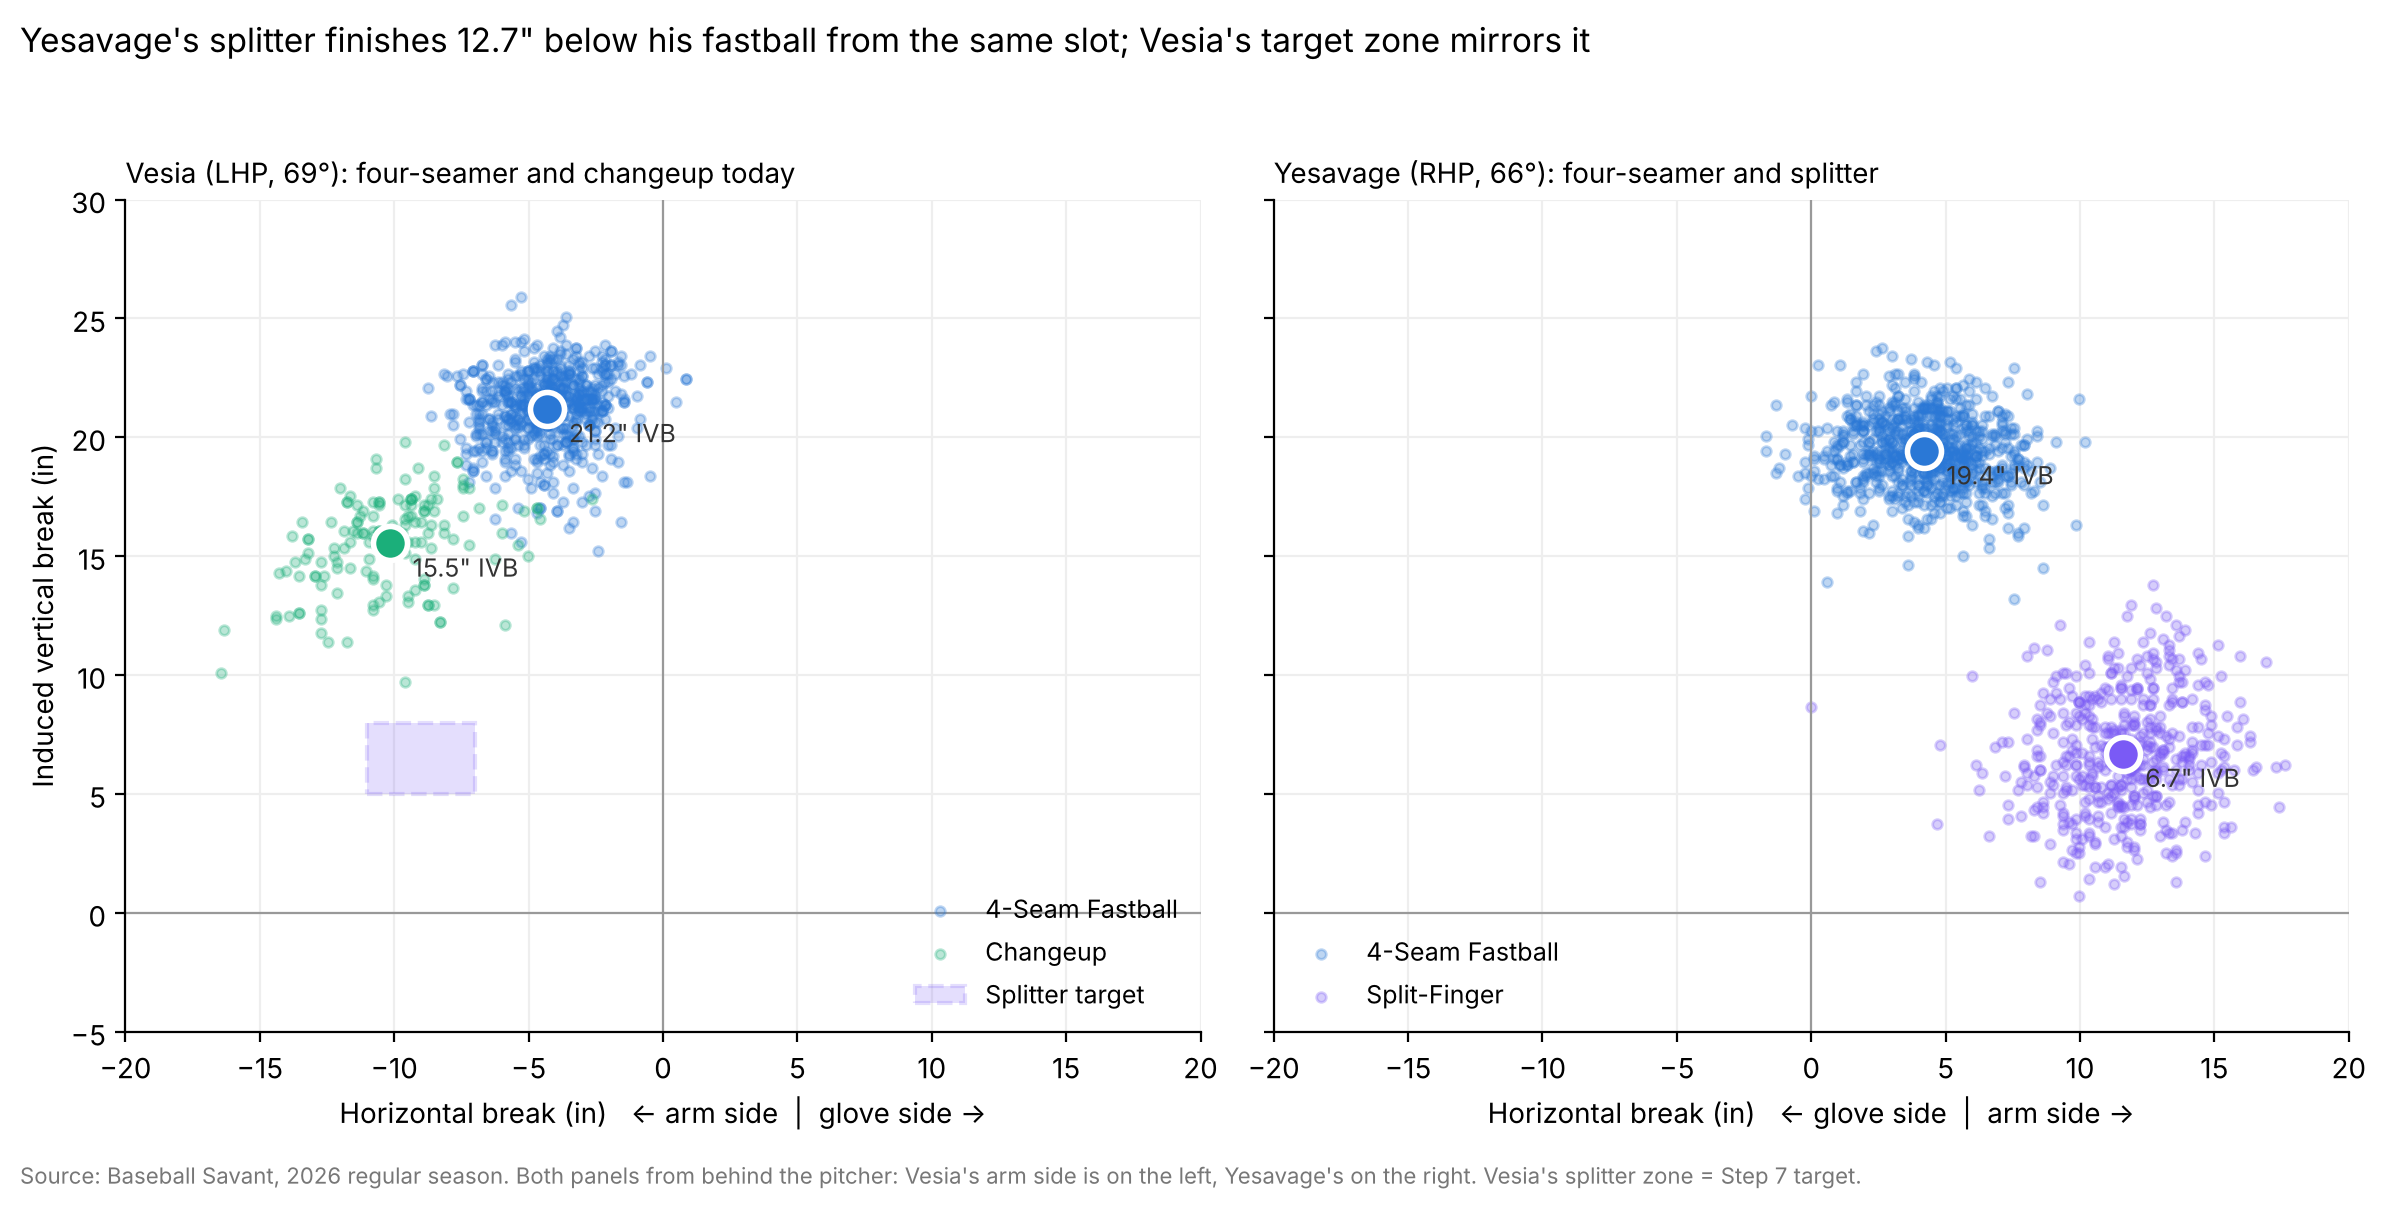

In [36]:
# STEP 9.5 — Vesia vs Yesavage, both from behind the pitcher
yesavage["hb_pitcher_view"] = -yesavage["pfx_x"] * 12

panels = [("Vesia (LHP, 69°): four-seamer and changeup today", vesia_clean,
           {"4-Seam Fastball": "#2a78d6", "Changeup": "#1baf7a"},
           "Horizontal break (in)   ← arm side  |  glove side →"),
          ("Yesavage (RHP, 66°): four-seamer and splitter", yesavage,
           {"4-Seam Fastball": "#2a78d6", "Split-Finger": "#7a5af5"},
           "Horizontal break (in)   ← glove side  |  arm side →")]

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True)

for ax, (title, data, pair_colors, xlabel) in zip(axes, panels):
    for pitch, color in pair_colors.items():
        p = data[data["pitch_name"] == pitch]
        ax.scatter(p["hb_pitcher_view"], p["ivb"], s=12, color=color, alpha=0.3, label=pitch)
        ax.scatter(p["hb_pitcher_view"].mean(), p["ivb"].mean(), s=150, color=color, edgecolor="white", linewidth=2, zorder=3)
        ax.annotate(f'{p["ivb"].mean():.1f}" IVB', xy=(p["hb_pitcher_view"].mean(), p["ivb"].mean()), xytext=(8, -12),
                    textcoords="offset points", fontsize=9, color="#333333")
    ax.axhline(0, color="#999999", linewidth=0.8)
    ax.axvline(0, color="#999999", linewidth=0.8)
    ax.set_title(title, fontsize=10, loc="left")
    ax.set_xlabel(xlabel)
    ax.grid(color="#eeeeee")
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].add_patch(Rectangle((-fs_target["hb_arm"][1], fs_target["ivb"][0]),
                            fs_target["hb_arm"][1] - fs_target["hb_arm"][0],
                            fs_target["ivb"][1] - fs_target["ivb"][0],
                            facecolor="#7a5af5", alpha=0.2, edgecolor="#7a5af5", linewidth=1.5, linestyle="--",
                            label="Splitter target"))
axes[0].legend(loc="lower right", frameon=False, fontsize=9)
axes[1].legend(loc="lower left", frameon=False, fontsize=9)

axes[0].set_ylabel("Induced vertical break (in)")
axes[0].set_xlim(-20, 20)
axes[0].set_ylim(-5, 30)
fig.suptitle("Yesavage's splitter finishes 12.7\" below his fastball from the same slot; Vesia's target zone mirrors it",
             fontsize=12, x=0.01, ha="left")
fig.text(0.01, 0.01, "Source: Baseball Savant, 2026 regular season. Both panels from behind the pitcher: Vesia's arm side is on the left, Yesavage's on the right. Vesia's splitter zone = Step 7 target.",
         fontsize=8, color="#777777")

plt.tight_layout(rect=(0, 0.03, 1, 0.95))
fig.savefig("../outputs/charts/step09_vesia_vs_yesavage.png", dpi=150)
plt.show()

**What I found:** Viewed from behind each pitcher, the two pairings are mirror images, since Vesia throws left-handed and Yesavage right-handed. The difference is in the vertical distance. Vesia's changeup sits just below and to the arm side of his fastball, with 15.5 inches of rise against 21.2, and the two clusters touch at their edges. Yesavage's splitter sits in a separate cluster far below his fastball, with 6.7 inches of rise against 19.4, in the mirror position of the target box drawn for Vesia.

**What I found in Step 9:** Trey Yesavage, the full-season splitter pitcher whose arm slot is closest to Vesia's, already throws the pitch this project proposes. His splitter leaves his hand from the same slot as his four-seamer, within 0.1 (degrees) of arm angle and about an inch of release side, and finishes 12.7 inches below it at 82.9 mph, 11.3 mph slower. Over 470 pitches it produced a 38.8% whiff rate and a .248 expected wOBA. Vesia's changeup gets comparable results today, but over only 149 pitches, from a release 6.6 (degrees) lower and almost 5 inches wider, and with only 5.7 inches of drop. A splitter built to the Step 7 target would give Vesia what Yesavage already has: a second pitch that hides behind his fastball's release and finishes more than a foot below it.

<a id="step-10"></a>
## Step 10: What's the story?

The previous nine steps built the case one measure at a time. A pitching coordinator, a coach and Vesia himself need it in a single picture. The hero chart reduces the project to the two numbers the whole argument rests on: how far the secondary pitch drops below the four-seamer, and how much its arm angle differs from the four-seamer's. It shows both for Vesia's changeup today, for the splitter target and for Yesavage's splitter, so the reader can see the problem, the proposal and the proof side by side.

### 10.1 The hero chart

The chart has two panels that share the same three rows. The left panel shows the drop below the four-seamer in inches of induced vertical break, and the right panel shows the difference in arm angle in degrees. Real pitches are solid bars; the splitter target is a dashed, lighter bar that covers its whole range, so it reads as a goal rather than a result. The values come from the comparison built in 9.4 and the targets stored in 7.1, so the chart updates if any of them change.

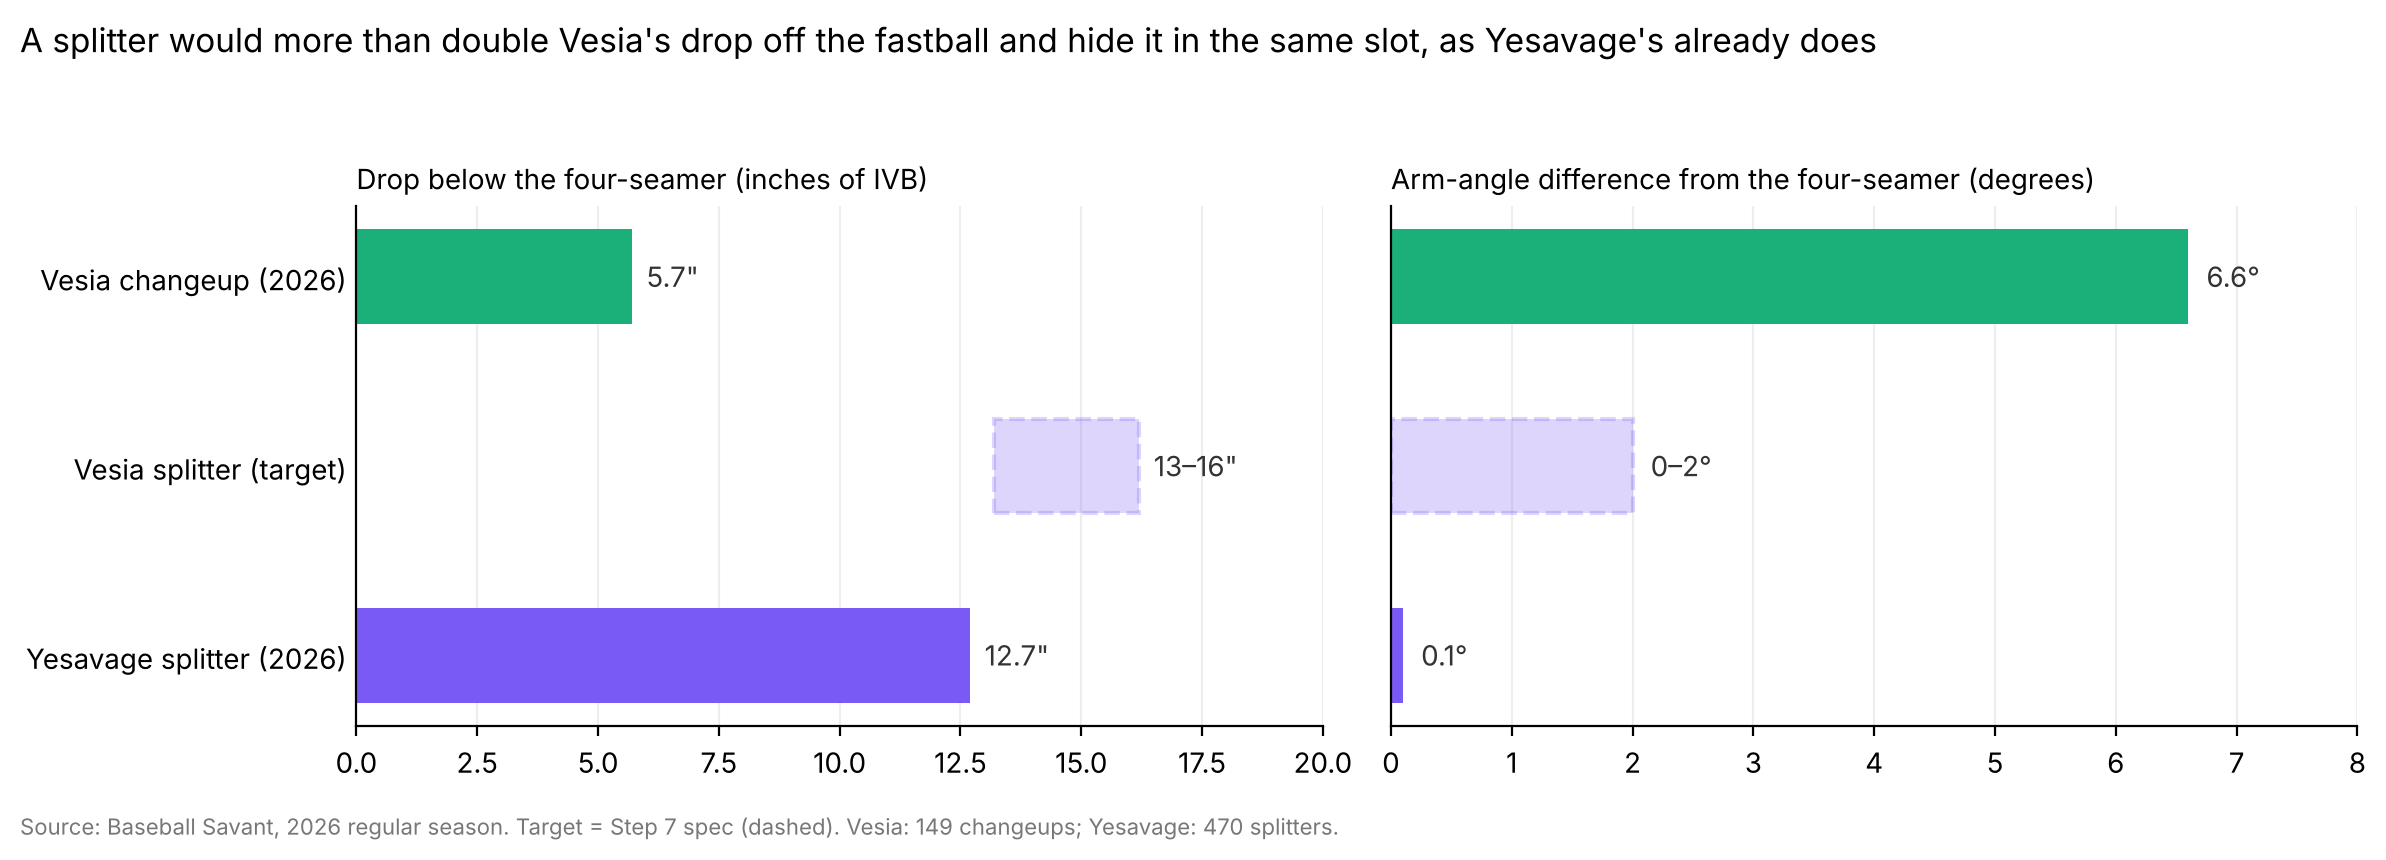

In [37]:
# STEP 10.1 — Hero chart
labels = ["Vesia changeup (2026)", "Vesia splitter (target)", "Yesavage splitter (2026)"]
drop = [abs(vesia_now[1]), None, abs(yesavage_fs[1])]
drop_target = (ff_ivb_mean - fs_target["ivb"][1], ff_ivb_mean - fs_target["ivb"][0])
slot_gap = [abs(vesia_now[3]), None, abs(yesavage_fs[3])]
slot_target = (0, 2)
bar_colors = ["#1baf7a", "#7a5af5", "#7a5af5"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
y = [2, 1, 0]

for i in [0, 2]:
    ax1.barh(y[i], drop[i], color=bar_colors[i], height=0.5)
    ax1.text(drop[i] + 0.3, y[i], f'{drop[i]:.1f}"', va="center", fontsize=10, color="#333333")
    ax2.barh(y[i], slot_gap[i], color=bar_colors[i], height=0.5)
    ax2.text(slot_gap[i] + 0.15, y[i], f'{slot_gap[i]:.1f}°', va="center", fontsize=10, color="#333333")

ax1.barh(y[1], drop_target[1] - drop_target[0], left=drop_target[0], color=bar_colors[1], alpha=0.25,
         height=0.5, edgecolor=bar_colors[1], linestyle="--", linewidth=1.5)
ax1.text(drop_target[1] + 0.3, y[1], f'{drop_target[0]:.0f}–{drop_target[1]:.0f}"', va="center", fontsize=10, color="#333333")
ax2.barh(y[1], slot_target[1] - slot_target[0], left=slot_target[0], color=bar_colors[1], alpha=0.25,
         height=0.5, edgecolor=bar_colors[1], linestyle="--", linewidth=1.5)
ax2.text(slot_target[1] + 0.15, y[1], "0–2°", va="center", fontsize=10, color="#333333")

ax1.set_yticks(y)
ax1.set_yticklabels(labels)
ax1.set_xlim(0, 20)
ax2.set_xlim(0, 8)
ax1.set_title("Drop below the four-seamer (inches of IVB)", fontsize=10, loc="left")
ax2.set_title("Arm-angle difference from the four-seamer (degrees)", fontsize=10, loc="left")
for ax in (ax1, ax2):
    ax.grid(axis="x", color="#eeeeee")
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="y", length=0)

fig.suptitle("A splitter would more than double Vesia's drop off the fastball and hide it in the same slot, as Yesavage's already does",
             fontsize=12, x=0.01, ha="left")
fig.text(0.01, 0.01, "Source: Baseball Savant, 2026 regular season. Target = Step 7 spec (dashed). Vesia: 149 changeups; Yesavage: 470 splitters.",
         fontsize=8, color="#777777")
plt.tight_layout(rect=(0, 0.04, 1, 0.93))
fig.savefig("../outputs/charts/step10_hero_splitter_case.png", dpi=150)
plt.show()

**What I found:** The hero chart sums up the project in two comparisons. Vesia's changeup drops 5.7 inches below his four-seamer and leaves his hand 6.6 (degrees) lower; the splitter target would drop 13 to 16 inches from within 2 (degrees) of the fastball's slot; and Yesavage's splitter already does both, dropping 12.7 inches from a slot just 0.1 (degrees) away. In one picture, the chart shows the problem, the proposed fix and a real MLB example that the fix works.

<a id="so-what"></a>
## So what

Alex Vesia should replace his changeup with a vertical splitter thrown from his fastball slot. His changeup finishes only 5.7 inches below his four-seamer and leaves his hand 6.6 (degrees) lower and almost 5 inches wider, so hitters get a pitch that neither drops away from the fastball nor hides behind it. A splitter at 82.5 to 84 mph, with 1,250 to 1,450 rpm of spin and 5 to 8 inches of rise, released within 2 (degrees) of his fastball's arm angle, would finish 13 to 16 inches below the four-seamer while looking the same out of the hand. Trey Yesavage, the full-season splitter pitcher with the arm slot closest to Vesia's, already throws that pitch: 12.7 inches below his fastball, from the same slot, with a 38.8% whiff rate over 470 pitches.

For a pitching coach, the message is that a pitch's value starts at release: a good secondary pitch has to move away from the fastball and come from the same window. For a player development department, this project shows how public Statcast data can turn a coaching idea into a measurable specification, with targets a bullpen session can test and results that can be tracked against a real MLB model.

## Limitations

The splitter in this project is a target, not a pitch Vesia throws, so its shape and results are estimates based on comparable pitchers rather than measurements. Yesavage is the closest model available, but he throws right-handed, about 2 mph harder, from a release point about a foot higher, and most of his 2026 pitches came between May and July, so his results show what the pairing can do rather than exactly what Vesia would get. Vesia's changeup sample is small, 149 pitches and 75 swings, which makes its strong 2026 results less reliable than they look. The league comparisons rest on 59 splitter pitchers, and only 10 of them throw from a slot of 50 (degrees) or higher, so the relationships between traits and results describe patterns, not causes. Finally, active spin comes from Savant's estimate rather than a direct measurement, and the project cannot account for factors that public data doesn't capture, such as grip, finger pressure, health or how comfortable Vesia would be learning a new pitch.

## Next steps

The natural next step is to test the specification in practice: track Vesia's splitter grips in bullpen sessions with a pitch-tracking device and a high-speed camera, and measure each throw against the Step 7 targets for spin, rise, arm-side run and arm angle. On the data side, the project could add pitch-location analysis to see where a splitter would be most effective against right-handed hitters, study how Yesavage sequences his splitter with his fastball by count, and repeat the same method on another high-slot reliever whose secondary pitch overlaps his fastball, to see whether the approach holds beyond one pitcher.